# **WADI A1 (2017) zero-day detection — v1: TabPFN density teacher vs. GMM baseline**

This notebook is `WADi_A2_2019_full_pipeline_v1.ipynb` pointed at the **A1 release** of WADI, with no surrogate. It produces the TabPFN teacher scores and the GMM scores that `WADI_A1_2017-baselines.ipynb` reads from `results/WADi_A1_2017_full_pipeline_v1/` (§4 of that notebook), so the TabPFN row and every paired comparison are filled in there.

#### What A1 is, and what it is not
`WADi_A1_2017_EDA_and_cleaning.ipynb` shows that A1 and A2 hold **the same plant data**: the attack days are identical, and A2's normal file is A1's minus two unstable spans (≈ 73 h and ≈ 45 h). A1 has no label column; its labels come from the official attack table (14 events including attack 13, which A2 does not label). A1 is therefore a **literature anchor, not an independent third dataset**: do not pool its results with WADI A2 as extra evidence.

#### Differences from the A2 pipeline
| item | A2 pipeline | this notebook |
|---|---|---|
| Clean files | `wadi2019_*` | `wadi2017_*` (A1, labels from the official table) |
| Normal span | A2's normal file (unstable spans already removed) | the full A1 normal file (FIT includes the unstable spans, as in the literature) |
| **CAL** | last 30% of the normal file | last 30% **minus rows in the A2-removed spans** (`cal_exclude_a2_removed = True`) |
| Surrogate | out of scope | out of scope (teacher vs. GMM only) |

**Why CAL is filtered.** In A1 the last 30% of the normal file reaches 9 Oct, and 46% of those rows lie in the unstable span 7 Oct 21:16 → 9 Oct 18:00 that A2 removed. A threshold taken from that span is far above anything in TEST and silences the detectors (GDN and TranAD raised no alarms in the first baselines run). Dropping those rows leaves CAL = 5 Oct 16:00 → 7 Oct 21:16, the same period A2 uses. FIT is left as it is, so the teacher context and the GMM still see the unstable span 29 Sep → 2 Oct.

**Keep the baselines notebook in step.** `WADI_A1_2017-baselines.ipynb` rebuilds the split and checks it row by row against this run. Its `DATA_CONFIG` needs the same `cal_exclude_a2_removed: True` and the matching filter in its split cell, or the check fails.

#### Evaluation protocol (unchanged from the A2 pipeline)
Chronological split (6 h warm-up dropped → FIT 70% → 1 h gap → CAL), TEST = the attack file. One threshold rule for all methods (CAL 1% quantile), static and adaptive. CAL and TEST are sampled every 10 s. Two views of uncertainty: row-block and event bootstrap (the event one is used for conclusions, with 14 attacks). Every table in §E/§F is rebuilt from saved files. Figures go to `output-figures/<name>_wadi2017_v1.png` at 600 dpi.


In [1]:
# Uncomment if the environment is missing dependencies.
# %pip install -q "tabpfn>=9.2" "tabpfn-extensions[unsupervised]>=0.6" scikit-learn pandas pyarrow numpy scipy matplotlib seaborn torch python-dotenv

## **0. Setup, configuration and versioning**

In [2]:
import gc
import hashlib
import importlib.metadata as importlib_metadata
import json
import os
import platform
import random
import re
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import torch
from scipy import stats
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import tabpfn
from tabpfn import TabPFNClassifier, TabPFNRegressor
from tabpfn_extensions.unsupervised import TabPFNUnsupervisedModel
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("tabpfn", tabpfn.__version__, "| torch", torch.__version__)

load_dotenv("/home/jaume/_DEVELOPMENT/_projects/secrets.env")   # adjust the path to where the file is
assert os.environ.get("TABPFN_TOKEN"), "TABPFN_TOKEN not found in secrets.env"

Device: cuda (NVIDIA GB10)
tabpfn 9.2.0 | torch 2.12.0+cu130


### **0.1 Configuration**

| block | changes … | cached in |
|---|---|---|
| `TEACHER_CONFIG` | data, split, feature views, TabPFN settings | `teacher/<teacher_fp>/members/` (one file per view × seed) |
| `GMM_CONFIG`, `EVAL_CONFIG` | baseline and evaluation | run directory (minutes) |

`SMOKE_TEST = True` runs end to end with tiny sizes into a separate run directory. Its results are not meaningful.

In [3]:
RUN_ID = "WADi_A1_2017_full_pipeline_v1"
FIG_VERSION = "wadi2017_v1"
FIG_DPI = 600
SMOKE_TEST = False

CLEAN_DIR = Path("scada-data/WaDI/WaDi/WaDi.A1_9-Oct-2017/clean")   # from WADi_A1_2017_EDA_and_cleaning.ipynb (v2)
FILE_PREFIX = "wadi2017"
RESULTS_ROOT = Path("results")
FIG_DIR = Path("output-figures")
SWAT_REFERENCE_DIR = RESULTS_ROOT / "SWaT_A1A2-full-pipeline-v3"   # for the cross-dataset comparison (§F3)

TEACHER_CONFIG = {
    "dataset": "WADI A1 (9 Oct 2017): clean v2, labels from the official attack table",
    # Chronological split (Plan §1)
    "drop_warmup": True,                  # first 6 h of the normal file (is_warmup)
    "fit_fraction": 0.70,
    "fit_cal_gap_rows": 3600,
    "post_attack_guard_steps": 30,
    "drop_a2_removed_spans": False,       # True = A2-like normal span (drops both unstable spans from FIT and CAL)
    "cal_exclude_a2_removed": True,       # CAL only from rows A2 kept (the span 7-9 Oct is far from TEST-like normal)
    "cal_stride": 10,
    "test_stride": 10,                    # must equal cal_stride (adaptive threshold)
    # Tags and feature views (Plan §3 + SWaT v3 learnings)
    "setpoint_tags": ["TOTAL_CONS_REQUIRED_FLOW"],   # plus every *_SP tag: state view only
    "exclude_types": ["AIT"],             # drifting / faulting analysers: out of every view (as SWaT v3)
    "max_mode_share": 0.99,               # drop sensors holding one value in >= 99% of FIT rows
    "actuator_exclude_types": ["LS", "AIT"],  # level-switch alarms are derived from the levels
    "include_actuators": True,
    "dedup_spearman": 0.98,               # FIT-only redundancy rule
    "detrend_window_s": 600,
    "dynamics_window_s": 60,
    "views": ["state", "detrend", "dynamics"],
    # TabPFN density teacher (same settings as SWaT v3)
    "teacher_seeds": [42, 43, 44],
    "context_size": 5000,
    "n_estimators": 1,
    "n_permutations": 4,
    "score_batch_size": 4096,
}
GMM_CONFIG = {"components_grid": [4, 8, 16, 32, 48, 64, 96, 128], "covariance": "full", "reg_covar": 1e-4,
              "fit_stride": 20, "seed": 42}
EVAL_CONFIG = {
    "fusions": {"fused": ["state", "detrend", "dynamics"], "fused-sd": ["state", "dynamics"]},
    "primary": "fused",                   # same headline fusion as SWaT v3
    "target_fpr": 0.01,
    "fpr_grid": [0.005, 0.01, 0.02, 0.05],
    "bootstrap_block_rows": 360,          # 360 rows x 10 s = 1 h
    "bootstrap_repeats": 1000,
    "bootstrap_seed": 2026,
    "adaptive_window_s": 86400,
    "adaptive_gap_s": 3600,
    "adaptive_min_history_s": 7200,
    "pauc_max_fpr": 0.10,
    "onset_s": 300,                       # WADI attacks are short (median ≈ 10 min)
}
# Measured on SWaT v3 (GB10, 4 permutations): ≈ 0.65 ms per scored row, per feature, per seed.
TABPFN_MS_PER_ROW_FEATURE = 0.65

if SMOKE_TEST:
    RUN_ID += "-smoke"
    FIG_VERSION += "-smoke"
    TEACHER_CONFIG.update({"teacher_seeds": [42], "context_size": 500, "cal_stride": 120, "test_stride": 120,
                           "n_permutations": 1})
    GMM_CONFIG["components_grid"] = [4, 8]
    EVAL_CONFIG.update({"bootstrap_repeats": 50, "bootstrap_block_rows": 30,
                        "adaptive_window_s": 21600, "adaptive_min_history_s": 3600})


def fingerprint(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:10]


TEACHER_FINGERPRINT = fingerprint(TEACHER_CONFIG)
RUN_FINGERPRINT = fingerprint([TEACHER_CONFIG, GMM_CONFIG, EVAL_CONFIG])
RUN_DIR = RESULTS_ROOT / RUN_ID
TEACHER_DIR = RUN_DIR / "teacher" / TEACHER_FINGERPRINT
for d in [RUN_DIR, TEACHER_DIR / "members", FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"


ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(), "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "tabpfn": tabpfn.__version__, "tabpfn_extensions": package_version("tabpfn-extensions"),
    "torch": torch.__version__, "scikit-learn": package_version("scikit-learn"),
    "pandas": pd.__version__, "numpy": np.__version__,
}
config_path = RUN_DIR / "config.json"
teacher_config_path = TEACHER_DIR / "teacher_config.json"
previous_teacher = json.loads(teacher_config_path.read_text()) if teacher_config_path.exists() else {}
teacher_config_path.write_text(json.dumps({
    "teacher_config": TEACHER_CONFIG, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "environment": previous_teacher.get("environment", ENVIRONMENT),
    "tabpfn_checkpoint": previous_teacher.get("tabpfn_checkpoint"),
    "created": previous_teacher.get("created", datetime.now().isoformat(timespec="seconds")),
}, indent=2))
config_path.write_text(json.dumps({
    "run_id": RUN_ID, "run_fingerprint": RUN_FINGERPRINT, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "teacher_dir": TEACHER_DIR.as_posix(), "teacher_config": TEACHER_CONFIG, "gmm_config": GMM_CONFIG,
    "eval_config": EVAL_CONFIG, "figures": {"dir": FIG_DIR.as_posix(), "version": FIG_VERSION, "dpi": FIG_DPI},
    "environment": ENVIRONMENT, "written": datetime.now().isoformat(timespec="seconds"),
}, indent=2))

print(f"RUN_ID:              {RUN_ID}")
print(f"Run fingerprint:     {RUN_FINGERPRINT}")
print(f"Teacher fingerprint: {TEACHER_FINGERPRINT}  -> {TEACHER_DIR}")
print(f"Figures:             {FIG_DIR}/<name>_{FIG_VERSION}.png @ {FIG_DPI} dpi")

RUN_ID:              WADi_A1_2017_full_pipeline_v1
Run fingerprint:     134969fe8e
Teacher fingerprint: 7b5a98dccd  -> results/WADi_A1_2017_full_pipeline_v1/teacher/7b5a98dccd
Figures:             output-figures/<name>_wadi2017_v1.png @ 600 dpi


### **0.2 Shared helpers**

These are the same definitions as SWaT v3, plus `event_bootstrap_indices`, which resamples attacks and normal blocks separately. Every score follows the same convention: **higher = more anomalous**.

In [4]:
def save_fig(fig, name):
    path = FIG_DIR / f"{name}_{FIG_VERSION}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"figure saved: {path}")


def post_attack_guard_mask(is_attack, guard_steps):
    # True = keep. Drops attack rows and the `guard_steps` rows right after each attack.
    is_attack = np.asarray(is_attack).astype(bool)
    keep = ~is_attack
    first_after_attack = np.flatnonzero(is_attack[:-1] & ~is_attack[1:]) + 1
    for start in first_after_attack:
        keep[start:start + guard_steps] = False
    return keep


def threshold_from_calibration(cal_scores, fpr):
    cal_scores = np.asarray(cal_scores)
    return float(np.quantile(cal_scores[np.isfinite(cal_scores)], 1.0 - fpr))


def point_metrics(y, scores, threshold):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(scores) >= threshold
    tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
    fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "roc_auc": roc_auc_score(y, scores),
        "average_precision": average_precision_score(y, scores),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "test_fpr": fp / (fp + tn) if fp + tn else 0.0,
        "accuracy": (tp + tn) / len(y),
    }


def contiguous_runs(mask):
    # Half-open (start, stop) index pairs of consecutive True values.
    padded = np.concatenate([[0], np.asarray(mask, dtype=np.int8), [0]])
    edges = np.diff(padded)
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def event_metrics(timestamps, y, pred, segments):
    ts = pd.DatetimeIndex(timestamps)
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    per_event = []
    for seg in segments.itertuples(index=False):
        lo = ts.searchsorted(seg.start, side="left")
        hi = ts.searchsorted(seg.end, side="right")
        hits = np.flatnonzero(pred[lo:hi])
        detected = hits.size > 0
        per_event.append({
            "segment": seg.segment,
            "attack_id": seg.attack_id,
            "attack_point": seg.attack_point,
            "start": seg.start,
            "duration_s": seg.duration_s,
            "test_rows": hi - lo,
            "detected": detected,
            "time_to_detect_s": (ts[lo + hits[0]] - seg.start).total_seconds() if detected else np.nan,
            "fraction_alarmed": float(pred[lo:hi].mean()) if hi > lo else np.nan,
        })
    per_event = pd.DataFrame(per_event)

    alarm_runs = contiguous_runs(pred)
    true_runs = sum(bool(y[a:b].any()) for a, b in alarm_runs)
    tp = int((pred & y).sum())
    point_precision = tp / pred.sum() if pred.sum() else 0.0
    event_recall = float(per_event["detected"].mean())
    summary = {
        "attacks_detected": int(per_event["detected"].sum()),
        "attacks_total": len(per_event),
        "event_recall": event_recall,
        "event_precision": true_runs / len(alarm_runs) if alarm_runs else 0.0,
        "alarm_runs": len(alarm_runs),
        "false_alarm_episodes": len(alarm_runs) - true_runs,
        "composite_f1": (2 * point_precision * event_recall / (point_precision + event_recall)
                         if point_precision + event_recall else 0.0),
        "median_ttd_s": float(per_event["time_to_detect_s"].median()),
    }
    return summary, per_event


def daily_false_alarm_rate(timestamps, y, pred):
    # Fraction of normal rows alarmed, per calendar day.
    normal = np.asarray(y) == 0
    days = pd.DatetimeIndex(timestamps).date
    return pd.Series(np.asarray(pred)[normal]).groupby(days[normal]).mean()


def adaptive_normalise(cal_scores, test_scores, stride_s, cfg):
    # Label-free online normalisation: (s_t - median) / IQR over the trailing window
    # [t - window, t - gap], counted in observed rows. CAL and TEST share the stride, so the
    # first TEST rows use the last CAL hours as their history (WADI: a gap of 2 days between the CAL end and the attack file).
    s = pd.Series(np.concatenate([cal_scores, test_scores]).astype(np.float64))
    window = int(cfg["adaptive_window_s"] / stride_s)
    gap = int(cfg["adaptive_gap_s"] / stride_s)
    min_rows = int(cfg["adaptive_min_history_s"] / stride_s)
    history = s.shift(gap).rolling(window, min_periods=min_rows)
    median = history.median()
    iqr = (history.quantile(0.75) - history.quantile(0.25)).where(lambda v: v > 0)
    z = ((s - median) / iqr).to_numpy()
    return z[:len(cal_scores)], z[len(cal_scores):]


def tpr_at_fpr(y, scores, fpr):
    f, t, _ = roc_curve(y, scores)
    return float(np.interp(fpr, f, t))


def block_bootstrap_indices(n, block, rng):
    # Circular block bootstrap: concatenate random wrap-around blocks of length `block`.
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return ((starts[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]


def event_bootstrap_indices(attack_units, normal_units, rng):
    # Stratified event bootstrap: resample whole attacks and whole normal blocks, separately.
    pick_a = rng.integers(0, len(attack_units), len(attack_units))
    pick_n = rng.integers(0, len(normal_units), len(normal_units))
    return np.concatenate([attack_units[i] for i in pick_a] + [normal_units[i] for i in pick_n])


def robust_z(values, reference):
    median = np.median(reference)
    iqr = np.subtract(*np.percentile(reference, [75, 25]))
    return (values - median) / (iqr if iqr > 0 else 1.0)


def shade_attacks(ax, segments, color="#e76f51", alpha=0.25):
    for seg in segments.itertuples(index=False):
        ax.axvspan(seg.start, seg.end, color=color, alpha=alpha, lw=0)

## **1. Load the clean WADI A1 files**

The files come from `WADi_A1_2017_EDA_and_cleaning.ipynb` (cleaning v2):
- **Timestamps** are parsed from `Date` + `Time` and verified against the 1 Hz `Row` counter for every row.
- **Labels.** A1 has no label column: `is_attack` is 1 inside the official attack windows (inclusive). Attacks 3 and 4 form one event (`3-4`).
- **`is_warmup`** flags the first 6 h of the normal file.
- **`a2_removed`** flags the normal-file rows that A2 dropped (two unstable spans). It is used for CAL only (`cal_exclude_a2_removed`), or for the whole normal span if `drop_a2_removed_spans` is set.

The normal file ends 1 s before the attack file starts, so the stream is one continuous block.


In [5]:
%%time
metadata = json.loads((CLEAN_DIR / f"{FILE_PREFIX}_metadata.json").read_text())
assert metadata.get("cleaning_version", 1) >= 2, "Re-run the cleaning notebook: the v2 file format is required."
normal_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_normal_clean.csv", parse_dates=["timestamp"])
attack_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_attack_clean.csv", parse_dates=["timestamp"], dtype={"attack_id": "string"})
segments = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_label_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
segments = segments[["segment", "start", "end", "duration_s", "attack_id", "attack_point"]]

assert normal_df["timestamp"].is_monotonic_increasing and attack_df["timestamp"].is_monotonic_increasing
assert normal_df["is_attack"].sum() == 0, "The normal file must be attack-free"
normal_df = normal_df[normal_df["timestamp"] < attack_df["timestamp"].min()]        # the two files must not overlap
if TEACHER_CONFIG["drop_a2_removed_spans"]:
    normal_df = normal_df[normal_df["a2_removed"] == 0]                              # A2-like normal span
normal_df = normal_df.reset_index(drop=True)
SENSORS_ALL = [s for s in metadata["sensors"] if s in normal_df.columns]
ACTUATORS_ALL = [a for a in metadata["actuators"] if a in normal_df.columns]
tags = SENSORS_ALL + ACTUATORS_ALL
missing_cells = {"normal": int(normal_df[tags].isna().sum().sum()), "attack": int(attack_df[tags].isna().sum().sum())}
normal_df[tags] = normal_df[tags].ffill().bfill()
attack_df[tags] = attack_df[tags].ffill().bfill()
print(f"Cells still missing after the cleaner's {metadata['ffill_limit_s']} s forward-fill (now filled): {missing_cells}")

display(segments)
print(f"Labelled segments: {len(segments)} | unlisted: {(segments['attack_id'] == 'unlisted').sum()} | "
      f"listed attacks without labelled rows: {metadata.get('listed_attacks_without_labels')}")

stream = pd.concat([normal_df.assign(source="normal"), attack_df.assign(source="attack")], ignore_index=True)
stream["is_warmup"] = stream["is_warmup"].fillna(0).astype(bool)
stream["a2_removed"] = stream["a2_removed"].fillna(0).astype(bool)
gaps = stream["timestamp"].diff().dt.total_seconds().fillna(1.0)
stream["block"] = (gaps != 1.0).cumsum()          # normal blocks + the attack file, no window crosses a gap
display(stream.groupby("block").agg(source=("source", "first"), start=("timestamp", "min"),
                                    end=("timestamp", "max"), rows=("timestamp", "size")))
print(f"Tags: {len(SENSORS_ALL)} sensors + {len(ACTUATORS_ALL)} actuators")


Cells still missing after the cleaner's 5 s forward-fill (now filled): {'normal': 15, 'attack': 0}


,segment,start,end,duration_s,attack_id,attack_point
0,1,2017-10-09 19:25:00,2017-10-09 19:50:16,1517.0,1,1_MV_001
1,2,2017-10-10 10:24:10,2017-10-10 10:34:00,591.0,2,1_FIT_001
2,3,2017-10-10 10:55:00,2017-10-10 11:24:00,1741.0,3-4,2_LT_002; 1_AIT_001
3,4,2017-10-10 11:30:40,2017-10-10 11:44:50,851.0,5,2_MCV_101..601
4,5,2017-10-10 13:39:30,2017-10-10 13:50:40,671.0,6,2_MCV_101; 2_MCV_201
5,6,2017-10-10 14:48:17,2017-10-10 15:00:32,736.0,7,1_AIT_002; 2_MV_003
6,7,2017-10-10 17:40:00,2017-10-10 17:49:40,581.0,8,2_MCV_007
7,8,2017-10-11 10:55:00,2017-10-11 10:56:27,88.0,9,1_P_005; 1_P_006
8,9,2017-10-11 11:17:54,2017-10-11 11:31:20,807.0,10,1_MV_001
9,10,2017-10-11 11:36:31,2017-10-11 11:47:00,630.0,11,2_MCV_007


Labelled segments: 14 | unlisted: 0 | listed attacks without labelled rows: []


,source,start,end,rows
block,,,,
0,normal,2017-09-25 18:00:00,2017-10-11 18:00:00,1382401


Tags: 69 sensors + 54 actuators
CPU times: user 4.1 s, sys: 478 ms, total: 4.58 s
Wall time: 4.58 s


## **2. Chronological split**

```
 normal file (25 Sep – 9 Oct)                                                  attack file (9–11 Oct)
 |-- warm-up 6 h --|------------ FIT (70%) ------------|gap 1h|-------- CAL candidates --------|------- TEST -------|
     dropped         TabPFN contexts, GMM fit, scalers          5 Oct 16:00 → 9 Oct 18:00         scored, never guarded
                                                                 CAL = those rows with a2_removed == 0
                                                                     (5 Oct 16:00 → 7 Oct 21:16)
```


In [6]:
assert TEACHER_CONFIG["cal_stride"] == TEACHER_CONFIG["test_stride"], "adaptive threshold needs equal CAL/TEST strides"
normal_mask = (stream["source"] == "normal").to_numpy(copy=True)
if TEACHER_CONFIG["drop_warmup"]:
    normal_mask &= ~stream["is_warmup"].to_numpy()
normal_pos = np.flatnonzero(normal_mask)
fit_end = int(TEACHER_CONFIG["fit_fraction"] * len(normal_pos))
fit_pos = normal_pos[:fit_end]
cal_pos = normal_pos[fit_end + TEACHER_CONFIG["fit_cal_gap_rows"]:]
if TEACHER_CONFIG["cal_exclude_a2_removed"]:
    cal_before = len(cal_pos)
    cal_pos = cal_pos[~stream["a2_removed"].to_numpy()[cal_pos]]
    print(f"CAL candidates in the A2-removed span dropped: {cal_before - len(cal_pos):,} of {cal_before:,} ({1 - len(cal_pos) / cal_before:.1%})")

guard = TEACHER_CONFIG["post_attack_guard_steps"]
fit_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[fit_pos], guard)
cal_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[cal_pos], guard)
fit_pos = fit_pos[fit_keep]
cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG["cal_stride"]]
test_pos = np.flatnonzero((stream["source"] == "attack").to_numpy())[::TEACHER_CONFIG["test_stride"]]
print(f"Post-attack guard rows removed: FIT {int((~fit_keep).sum())}, CAL {int((~cal_keep).sum())} (TEST: not applied)")
print(f"FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)")

CAL candidates in the A2-removed span dropped: 161,029 of 352,800 (45.6%)
Post-attack guard rows removed: FIT 0, CAL 0 (TEST: not applied)
FIT 831,600 rows (1 Hz) | CAL 19,178 | TEST 17,281 (every 10 s)


## **3. Tag selection and feature views**

All selection rules use **FIT only** and no labels:
1. **Set points / demand** (`*_SP`, `TOTAL_CONS_REQUIRED_FLOW`) go into the state view only.
2. **Continuous sensors** = the remaining sensors, without the analysers (AIT) and without sensors that hold one value in ≥ 99% of FIT rows. Near-duplicates (|Spearman| ≥ 0.98) are removed greedily, keeping the first in tag order.
3. **Actuators** = those that change during FIT, excluding level-switch alarms and AIT tags, de-duplicated with the same rule.

| View | Features | What it sees |
|---|---|---|
| **state** | continuous sensors + set points + actuators | *Where* the plant is (level-drift sensitive) |
| **detrend** | each continuous sensor − causal 600 s trailing mean | *What just changed* (onsets) |
| **dynamics** | log₁₀(rolling std over 60 s + ε) of each continuous sensor | *Whether the plant is moving* (the strongest SWaT view) |

Rolling features are computed separately for each contiguous block, so no window crosses a recording gap.

In [7]:
%%time
def tag_type(tag):
    parts = tag.split("_")
    return parts[1] if len(parts) > 2 else parts[0]


def dedup(tags, frame, threshold):
    # Greedy, label-free: keep a tag unless it is a near-copy (|Spearman| >= threshold) of one already kept.
    corr = frame[tags].rank().corr().abs()
    kept = []
    for t in tags:
        if not any(corr.at[t, k] >= threshold for k in kept):
            kept.append(t)
    return kept


fit_raw = stream.iloc[fit_pos]
fit_sample = fit_raw.iloc[::20]
varies = lambda t: fit_raw[t].nunique() > 1
SETPOINTS = [s for s in SENSORS_ALL if (s.endswith("_SP") or s in TEACHER_CONFIG["setpoint_tags"]) and varies(s)]
mode_share = lambda t: fit_raw[t].value_counts(normalize=True).iloc[0]
candidates = [s for s in SENSORS_ALL if s not in SETPOINTS and not s.endswith("_SP") and varies(s)]
EXCLUDED_TYPE = [s for s in candidates if tag_type(s) in TEACHER_CONFIG["exclude_types"]]
NEAR_CONSTANT = [s for s in candidates if s not in EXCLUDED_TYPE and mode_share(s) >= TEACHER_CONFIG["max_mode_share"]]
candidates = [s for s in candidates if s not in EXCLUDED_TYPE and s not in NEAR_CONSTANT]
CONTINUOUS = dedup(candidates, fit_sample, TEACHER_CONFIG["dedup_spearman"])
act_candidates = [a for a in ACTUATORS_ALL if varies(a) and tag_type(a) not in TEACHER_CONFIG["actuator_exclude_types"]]
ACTUATORS_USED = dedup(act_candidates, fit_sample, TEACHER_CONFIG["dedup_spearman"]) if TEACHER_CONFIG["include_actuators"] else []
ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if not varies(a)]
W = TEACHER_CONFIG["detrend_window_s"]
WS = TEACHER_CONFIG["dynamics_window_s"]
DYN_EPS = (1e-3 * fit_raw[CONTINUOUS].std() + 1e-9).to_numpy()

VIEW_FEATURES = {
    "state": CONTINUOUS + SETPOINTS + ACTUATORS_USED,
    "detrend": [f"{s}_dt{W}" for s in CONTINUOUS],
    "dynamics": [f"{s}_sd{WS}" for s in CONTINUOUS],
}
VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG["views"]}
ALL_FEATURES = list(dict.fromkeys(f for v in VIEW_FEATURES.values() for f in v))


def build_features(raw):
    # Causal detrend and dynamics features of one contiguous 1 Hz block.
    sensors = raw[CONTINUOUS].astype(np.float64)
    detrend = sensors - sensors.rolling(W, min_periods=1).mean()
    detrend.columns = [f"{s}_dt{W}" for s in CONTINUOUS]
    dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
    dynamics.columns = [f"{s}_sd{WS}" for s in CONTINUOUS]
    return pd.concat([detrend, dynamics], axis=1).astype(np.float32)


derived = pd.concat([build_features(block) for _, block in stream.groupby("block", sort=False)])
stream = pd.concat([stream, derived], axis=1)

fit_df = stream.iloc[fit_pos].reset_index(drop=True)
cal_df = stream.iloc[cal_pos].reset_index(drop=True)
test_df = stream.iloc[test_pos].reset_index(drop=True)
test_df["attack_id"] = "normal"
for seg in segments.itertuples(index=False):
    test_df.loc[test_df["timestamp"].between(seg.start, seg.end), "attack_id"] = seg.attack_id
constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
assert not constant, f"Constant features in FIT: {constant}"
assert fit_df["timestamp"].max() < cal_df["timestamp"].min() < test_df["timestamp"].min()
y_test = test_df["is_attack"].to_numpy().astype(int)

print(f"Set points in the state view ({len(SETPOINTS)}): {SETPOINTS}")
print(f"Continuous sensors ({len(CONTINUOUS)}), removed as near-duplicates: {[c for c in candidates if c not in CONTINUOUS]}")
print(f"Excluded by type {TEACHER_CONFIG['exclude_types']}: {EXCLUDED_TYPE}")
print(f"Near-constant in FIT (mode share ≥ {TEACHER_CONFIG['max_mode_share']}): {NEAR_CONSTANT}")
print(f"Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}")
print(f"Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}")
print({v: len(f) for v, f in VIEW_FEATURES.items()}, "features per view")

split_summary = pd.DataFrame([
    {"split": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(),
     "rows": len(frame), "stride_s": stride, "attack_rows": int(frame["is_attack"].sum())}
    for name, frame, stride in [("FIT", fit_df, 1), ("CAL", cal_df, TEACHER_CONFIG["cal_stride"]),
                                ("TEST", test_df, TEACHER_CONFIG["test_stride"])]
])
split_summary["attack_share"] = split_summary["attack_rows"] / split_summary["rows"]
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
display(split_summary)

Set points in the state view (7): ['2_FIC_101_SP', '2_FIC_201_SP', '2_FIC_301_SP', '2_FIC_401_SP', '2_FIC_501_SP', '2_FIC_601_SP', 'TOTAL_CONS_REQUIRED_FLOW']
Continuous sensors (35), removed as near-duplicates: ['2_FQ_101_PV', '2_FQ_201_PV', '2_FQ_301_PV', '2_FQ_401_PV', '2_FQ_501_PV', '2_FQ_601_PV', '2_PIT_003_PV']
Excluded by type ['AIT']: ['1_AIT_001_PV', '1_AIT_002_PV', '1_AIT_003_PV', '1_AIT_004_PV', '1_AIT_005_PV', '2A_AIT_001_PV', '2A_AIT_002_PV', '2A_AIT_003_PV', '2A_AIT_004_PV', '2B_AIT_001_PV', '2B_AIT_002_PV', '2B_AIT_003_PV', '2B_AIT_004_PV', '3_AIT_001_PV', '3_AIT_002_PV', '3_AIT_003_PV', '3_AIT_004_PV', '3_AIT_005_PV']
Near-constant in FIT (mode share ≥ 0.99): []
Actuators in the state view (12): ['1_MV_001_STATUS', '1_MV_004_STATUS', '1_P_005_STATUS', '2_MV_003_STATUS', '2_MV_006_STATUS', '2_MV_101_STATUS', '2_MV_201_STATUS', '2_MV_301_STATUS', '2_MV_401_STATUS', '2_MV_501_STATUS', '2_MV_601_STATUS', '2_P_003_STATUS']
Actuators constant in FIT (28): ['1_LS_001_AL', '1_L

,split,start,end,rows,stride_s,attack_rows,attack_share
0,FIT,2017-09-26 00:00:00,2017-10-05 14:59:59,831600,1,0,0.000000
1,CAL,2017-10-05 16:00:00,2017-10-07 21:16:10,19178,10,0,0.000000
2,TEST,2017-10-09 18:00:00,2017-10-11 18:00:00,17281,10,1007,0.058272


CPU times: user 3.19 s, sys: 567 ms, total: 3.76 s
Wall time: 3.76 s


In [8]:
# Diagnostic only: actuator states in TEST that never occur in FIT (not used by any detector).
fit_states = {a: set(fit_raw[a].unique()) for a in ACTUATORS_ALL}
unseen = pd.DataFrame({a: ~test_df[a].isin(fit_states[a]) for a in ACTUATORS_ALL})
any_unseen = unseen.any(axis=1).to_numpy()
y_bool = y_test.astype(bool)
ts_test = pd.DatetimeIndex(test_df["timestamp"])
attacks_with_unseen = sum(
    bool(any_unseen[ts_test.searchsorted(s.start):ts_test.searchsorted(s.end, side="right")].any())
    for s in segments.itertuples(index=False))
unseen_table = pd.DataFrame({
    "FIT states": [sorted(fit_states[a]) for a in ACTUATORS_ALL],
    "TEST attack rows in unseen state": unseen[y_bool].sum().to_numpy(),
    "TEST normal rows in unseen state": unseen[~y_bool].sum().to_numpy(),
}, index=ACTUATORS_ALL)
unseen_table = unseen_table[(unseen_table.iloc[:, 1] + unseen_table.iloc[:, 2]) > 0]
print(f"TEST rows with ≥1 actuator in a never-seen state: attack {any_unseen[y_bool].mean():.1%} | normal {any_unseen[~y_bool].mean():.1%}")
print(f"Attacks with ≥1 such row: {attacks_with_unseen} / {len(segments)}")
display(unseen_table)
unseen_table.to_csv(RUN_DIR / "diagnostic_unseen_actuator_states.csv")

TEST rows with ≥1 actuator in a never-seen state: attack 14.2% | normal 0.1%
Attacks with ≥1 such row: 3 / 14


,FIT states,TEST attack rows in unseen state,TEST normal rows in unseen state
1_MV_002_STATUS,[1],135,19
1_MV_003_STATUS,[1],135,19
1_P_006_STATUS,[1],8,0


figure saved: output-figures/split_and_views_wadi2017_v1.png


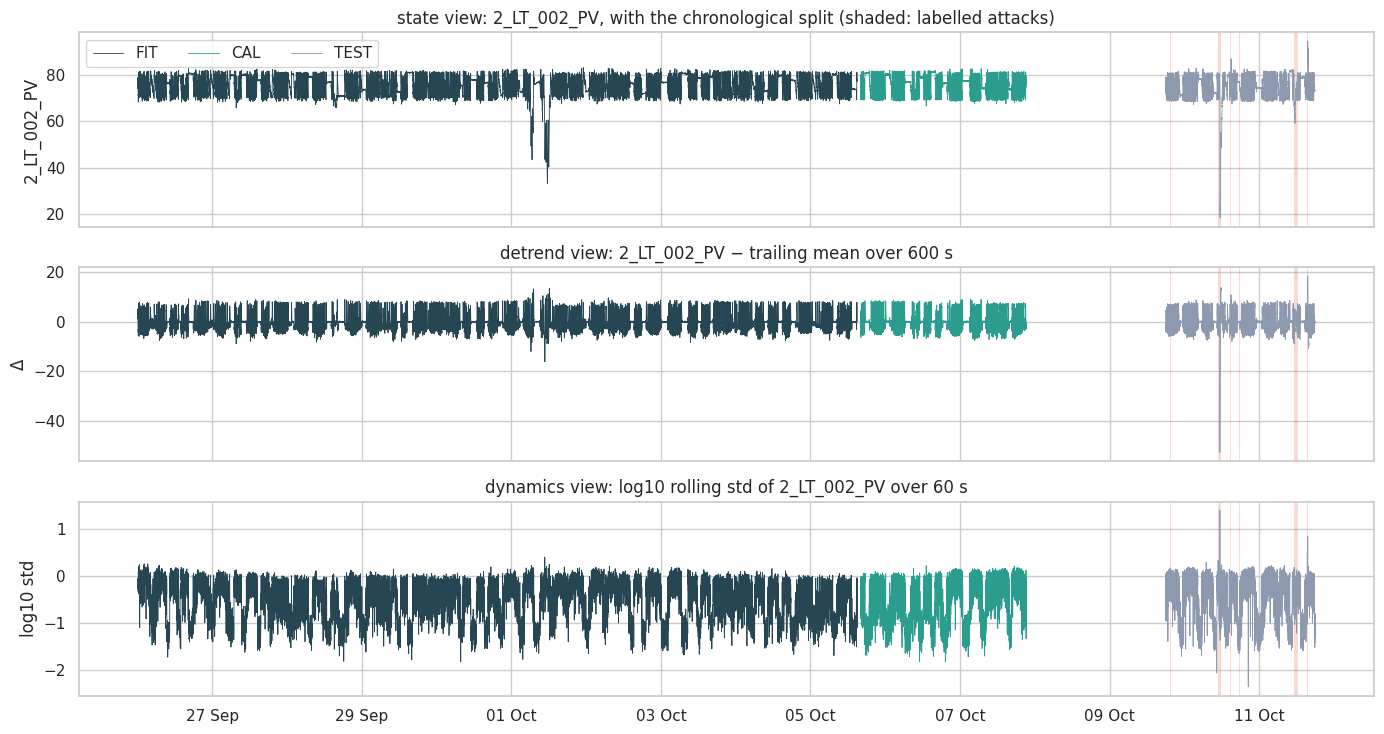

In [9]:
tag = "2_LT_002_PV" if "2_LT_002_PV" in CONTINUOUS else CONTINUOUS[0]
fig, axes = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
for name, frame, color in [("FIT", fit_df.iloc[::60], "#264653"), ("CAL", cal_df, "#2a9d8f"), ("TEST", test_df, "#8d99ae")]:
    axes[0].plot(frame["timestamp"], frame[tag], lw=0.6, color=color, label=name)
    axes[1].plot(frame["timestamp"], frame[f"{tag}_dt{W}"], lw=0.6, color=color)
    axes[2].plot(frame["timestamp"], frame[f"{tag}_sd{WS}"], lw=0.6, color=color)
for ax in axes:
    shade_attacks(ax, segments)
axes[0].set(title=f"state view: {tag}, with the chronological split (shaded: labelled attacks)", ylabel=tag)
axes[1].set(title=f"detrend view: {tag} − trailing mean over {W} s", ylabel="Δ")
axes[2].set(title=f"dynamics view: log10 rolling std of {tag} over {WS} s", ylabel="log10 std")
axes[0].legend(loc="upper left", ncol=3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
save_fig(fig, "split_and_views")
plt.show()

### **3.1 Drift per feature and view**

Two descriptive measures, neither used for selection: the KS statistic between FIT and normal TEST rows, and the fraction of TEST rows outside the FIT range.

In [10]:
test_normal_rows = test_df.loc[test_df["is_attack"] == 0]
drift = pd.DataFrame([
    {"feature": f, "view": v,
     "ks_fit_vs_cal": stats.ks_2samp(fit_df[f].iloc[::10], cal_df[f]).statistic,
     "ks_fit_vs_test_normal": stats.ks_2samp(fit_df[f].iloc[::10], test_normal_rows[f]).statistic,
     "test_outside_fit_range": ((test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max())).mean()}
    for v, feats in VIEW_FEATURES.items() for f in feats
])
drift.to_csv(RUN_DIR / "drift_per_feature.csv", index=False)
display(drift.groupby("view")[["ks_fit_vs_cal", "ks_fit_vs_test_normal", "test_outside_fit_range"]].agg(["mean", "max"]).round(3))
for v, feats in VIEW_FEATURES.items():
    outside = np.any([(test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max()) for f in feats], axis=0).mean()
    print(f"{v:9s}: TEST rows with ≥1 feature outside the FIT range: {outside:.1%}")

ks_fit_vs_cal        ks_fit_vs_test_normal         \
                  mean    max                  mean    max   
view                                                         
detrend          0.032  0.079                 0.028  0.052   
dynamics         0.216  0.584                 0.208  0.791   
state            0.070  0.244                 0.069  0.284   

         test_outside_fit_range         
                           mean    max  
view                                    
detrend                   0.000  0.003  
dynamics                  0.000  0.001  
state                     0.001  0.011

state    : TEST rows with ≥1 feature outside the FIT range: 2.3%
detrend  : TEST rows with ≥1 feature outside the FIT range: 1.0%
dynamics : TEST rows with ≥1 feature outside the FIT range: 0.3%


## **4. Teacher contexts and scalers**

Each seed draws a **time-stratified** context of `context_size` FIT rows, one random row per consecutive time bin. The same row indices are used for every view. One `StandardScaler` per view is fitted on FIT and shared by TabPFN and the GMM.

In [11]:
def time_stratified_context(n_rows, size, seed):
    rng = np.random.default_rng(seed)
    bins = np.array_split(np.arange(n_rows), size)
    return np.array([rng.choice(b) for b in bins if len(b)])


context_indices = {s: time_stratified_context(len(fit_df), TEACHER_CONFIG["context_size"], s)
                   for s in TEACHER_CONFIG["teacher_seeds"]}
view_scalers = {v: StandardScaler().fit(fit_df[f].to_numpy(np.float32)) for v, f in VIEW_FEATURES.items()}


def scaled(view, frame):
    return view_scalers[view].transform(frame[VIEW_FEATURES[view]].to_numpy(np.float32)).astype(np.float32)


rows_per_member = len(cal_df) + len(test_df)
est_min = {v: TABPFN_MS_PER_ROW_FEATURE * len(f) * rows_per_member / 60000 for v, f in VIEW_FEATURES.items()}
n_seeds = len(TEACHER_CONFIG["teacher_seeds"])
print("Context sizes:", {s: len(i) for s, i in context_indices.items()})
print(f"Rows to score per (view, seed): cal={len(cal_df):,} + test={len(test_df):,}")
print("Estimated TabPFN minutes per seed:", {v: round(m) for v, m in est_min.items()},
      f"→ total ≈ {sum(est_min.values()) * n_seeds / 60:.1f} h for {n_seeds} seeds (cached per member)")

Context sizes: {42: 5000, 43: 5000, 44: 5000}
Rows to score per (view, seed): cal=19,178 + test=17,281
Estimated TabPFN minutes per seed: {'state': 21, 'detrend': 14, 'dynamics': 14} → total ≈ 2.4 h for 3 seeds (cached per member)


## **Part B — TabPFN density teachers, one per view**

For each view and seed, `TabPFNUnsupervisedModel` is fitted on that seed's context, and the chain-rule log-density is computed for CAL and TEST.

- **Score** = −log-density, turned into a robust z-score per member against its own CAL scores: (s − median_CAL) / IQR_CAL.
- **View teacher** = mean over seeds.
- **Fusions** are computed identically for TabPFN and the GMM: `fused` = mean of the three views (the SWaT v3 primary), `fused-sd` = mean of state + dynamics, and `fused-max` = max over the three views.
- **Caching.** Each (view, seed) member is saved in `teacher/<teacher_fp>/members/` as soon as it is done, so an interrupted run resumes where it stopped.

In [12]:
class DensityCompatibleTabPFNRegressor(TabPFNRegressor):
    # Align full-output logits with the density criterion's bin boundaries.

    def predict(self, X, **kwargs):
        prediction = super().predict(X, **kwargs)
        if kwargs.get("output_type") == "full":
            # TabPFN can return float32 logits with float64 borders, which makes
            # BarDistribution fail inside the extension; align dtype and device.
            borders = prediction["criterion"].borders
            prediction = dict(prediction)
            prediction["logits"] = torch.as_tensor(prediction["logits"]).to(
                dtype=borders.dtype, device=borders.device
            )
        return prediction


def finite_anomaly_score(log_density):
    values = np.asarray(log_density, dtype=np.float64)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return np.zeros_like(values)
    clean = np.nan_to_num(values, nan=finite.min(), neginf=finite.min(), posinf=finite.max())
    return -clean


def score_in_batches(model, X, batch_size, n_permutations, permutation_seed):
    chunks = []
    for start in range(0, len(X), batch_size):
        random.seed(permutation_seed)          # same chain-rule orders for every batch
        result = model.outliers(
            torch.as_tensor(X[start:start + batch_size], dtype=torch.float32),
            n_permutations=n_permutations,
        )
        chunks.append(result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result))
    return finite_anomaly_score(np.concatenate(chunks))


def make_teacher(seed):
    kw = dict(n_estimators=TEACHER_CONFIG["n_estimators"], device=DEVICE, random_state=seed,
              memory_saving_mode="auto", show_progress_bar=False)
    return TabPFNUnsupervisedModel(tabpfn_clf=TabPFNClassifier(**kw), tabpfn_reg=DensityCompatibleTabPFNRegressor(**kw))

In [13]:
%%time
SPLITS = {"cal": cal_df, "test": test_df}
teacher_members = {}          # (view, seed) -> {split: scores, f"sec_{split}": seconds}
tabpfn_checkpoint = None

for view in VIEW_FEATURES:
    X_pool = scaled(view, fit_df)
    X_splits = {name: scaled(view, frame) for name, frame in SPLITS.items()}
    for seed in TEACHER_CONFIG["teacher_seeds"]:
        path = TEACHER_DIR / "members" / f"{view}_seed_{seed}.npz"
        member = dict(np.load(path)) if path.exists() else {}
        missing = [s for s in X_splits if s not in member]
        if not missing:
            print(f"{view:9s} seed {seed}: loaded from cache")
            teacher_members[(view, seed)] = member
            continue

        torch.manual_seed(seed)
        model = make_teacher(seed)
        model.fit(X_pool[context_indices[seed]])
        for split in missing:
            t0 = time.time()
            member[split] = score_in_batches(model, X_splits[split], TEACHER_CONFIG["score_batch_size"],
                                             TEACHER_CONFIG["n_permutations"], permutation_seed=seed)
            member[f"sec_{split}"] = np.array(time.time() - t0)
            print(f"{view:9s} seed {seed}: scored {split:5s} ({len(X_splits[split]):,} rows × {X_splits[split].shape[1]} features) "
                  f"in {float(member[f'sec_{split}']) / 60:.1f} min")
            np.savez(path, **member)
        teacher_members[(view, seed)] = member

        if tabpfn_checkpoint is None:
            configs = getattr(getattr(model, "tabpfn_reg", None), "configs_", None) or []
            tabpfn_checkpoint = getattr(configs[0], "name", None) if configs else None
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

if tabpfn_checkpoint:
    record = json.loads(teacher_config_path.read_text())
    record["tabpfn_checkpoint"] = tabpfn_checkpoint
    teacher_config_path.write_text(json.dumps(record, indent=2))
print("TabPFN checkpoint:", json.loads(teacher_config_path.read_text()).get("tabpfn_checkpoint"))

state     seed 42: scored cal   (19,178 rows × 54 features) in 11.5 min
state     seed 42: scored test  (17,281 rows × 54 features) in 11.1 min
state     seed 43: scored cal   (19,178 rows × 54 features) in 11.4 min
state     seed 43: scored test  (17,281 rows × 54 features) in 11.1 min
state     seed 44: scored cal   (19,178 rows × 54 features) in 11.5 min
state     seed 44: scored test  (17,281 rows × 54 features) in 11.1 min
detrend   seed 42: scored cal   (19,178 rows × 35 features) in 6.6 min
detrend   seed 42: scored test  (17,281 rows × 35 features) in 6.3 min
detrend   seed 43: scored cal   (19,178 rows × 35 features) in 6.6 min
detrend   seed 43: scored test  (17,281 rows × 35 features) in 6.3 min
detrend   seed 44: scored cal   (19,178 rows × 35 features) in 6.6 min
detrend   seed 44: scored test  (17,281 rows × 35 features) in 6.4 min
dynamics  seed 42: scored cal   (19,178 rows × 35 features) in 6.6 min
dynamics  seed 42: scored test  (17,281 rows × 35 features) in 6.3 min


### **B1. Calibrate, fuse and save the teacher scores**

| File | Rows | Contents |
|---|---|---|
| `teacher/<fp>/teacher_cal.parquet` | later normal rows, no labels | timestamp, all view features, `teacher_<view>`, per-seed columns, `teacher_fused`, `teacher_fused-sd`, `teacher_fused-max` |
| `teacher/<fp>/teacher_test.parquet` | attack period | same + `is_attack`, `attack_id` |

In [14]:
seeds = TEACHER_CONFIG["teacher_seeds"]
views = list(VIEW_FEATURES)
FUSIONS = {name: [v for v in members if v in views] for name, members in EVAL_CONFIG["fusions"].items()}


def add_fusions(per_view):
    # The same fusion rule for TabPFN and the GMM: inputs are CAL-calibrated robust z-scores per view.
    out = dict(per_view)
    for name, members in FUSIONS.items():
        out[name] = np.mean([per_view[v] for v in members], axis=0)
    out["fused-max"] = np.max([per_view[v] for v in views], axis=0)
    return out


member_z = {(v, s, split): robust_z(teacher_members[(v, s)][split], teacher_members[(v, s)]["cal"])
            for v in views for s in seeds for split in SPLITS}
teacher_files = {}
for split, frame in SPLITS.items():
    extra = ["is_attack", "attack_id"] if split == "test" else []
    out = frame[["timestamp"] + ALL_FEATURES + extra].copy()
    per_view = {v: np.mean([member_z[(v, s, split)] for s in seeds], axis=0) for v in views}
    for name, scores in add_fusions(per_view).items():
        out[f"teacher_{name}"] = scores
    for v in views:
        for s in seeds:
            out[f"teacher_{v}_seed_{s}"] = member_z[(v, s, split)]
    out.attrs = {}
    out.to_parquet(TEACHER_DIR / f"teacher_{split}.parquet", index=False)
    teacher_files[split] = out
segments.to_csv(TEACHER_DIR / "attack_segments.csv", index=False)
(TEACHER_DIR / "features.json").write_text(json.dumps({"views": VIEW_FEATURES, "all": ALL_FEATURES}))

teacher_cost = pd.DataFrame([
    {"view": v, "seed": s, "n_features": len(VIEW_FEATURES[v]),
     "seconds": sum(float(teacher_members[(v, s)].get(f"sec_{k}", np.nan)) for k in SPLITS),
     "rows_scored": rows_per_member} for v in views for s in seeds
])
teacher_cost["ms_per_row"] = 1000 * teacher_cost["seconds"] / teacher_cost["rows_scored"]
teacher_cost.to_csv(TEACHER_DIR / "teacher_cost.csv", index=False)
print("Saved teacher scores to", TEACHER_DIR.resolve())
display(teacher_cost.round(2))

Saved teacher scores to /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/WADi_A1_2017_full_pipeline_v1/teacher/7b5a98dccd


,view,seed,n_features,seconds,rows_scored,ms_per_row
0,state,42,54,1352.60,36459,37.10
1,state,43,54,1352.46,36459,37.10
2,state,44,54,1358.18,36459,37.25
3,detrend,42,35,774.56,36459,21.24
4,detrend,43,35,774.93,36459,21.25
5,detrend,44,35,778.33,36459,21.35
6,dynamics,42,35,775.02,36459,21.26
7,dynamics,43,35,773.71,36459,21.22
8,dynamics,44,35,774.11,36459,21.23


### **B2. Teacher results at the static CAL threshold**

,threshold,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy,recall_onset,recall_sustained
teacher,,,,,,,,,,
teacher_state,1.8172,0.7312,0.3210,0.5390,0.3019,0.3870,0.0160,0.9443,0.3077,0.2982
teacher_detrend,1.4299,0.7293,0.2561,0.4544,0.2175,0.2942,0.0162,0.9392,0.3769,0.1167
teacher_dynamics,1.1321,0.6984,0.2098,0.4267,0.1271,0.1959,0.0106,0.9392,0.2462,0.0519
teacher_fused,1.2567,0.7368,0.2951,0.4055,0.2493,0.3087,0.0226,0.9350,0.4128,0.1459
teacher_fused-sd,1.3824,0.7351,0.2980,0.4664,0.2066,0.2863,0.0146,0.9400,0.2974,0.1491
teacher_fused-max,1.8274,0.7383,0.3260,0.5098,0.3088,0.3847,0.0184,0.9424,0.3128,0.3063


,mean,std,min,max
view,,,,
detrend,0.7290,0.0050,0.7246,0.7344
dynamics,0.6979,0.0042,0.6953,0.7027
state,0.7355,0.0219,0.7113,0.7539


figure saved: output-figures/teacher_roc_daily_wadi2017_v1.png


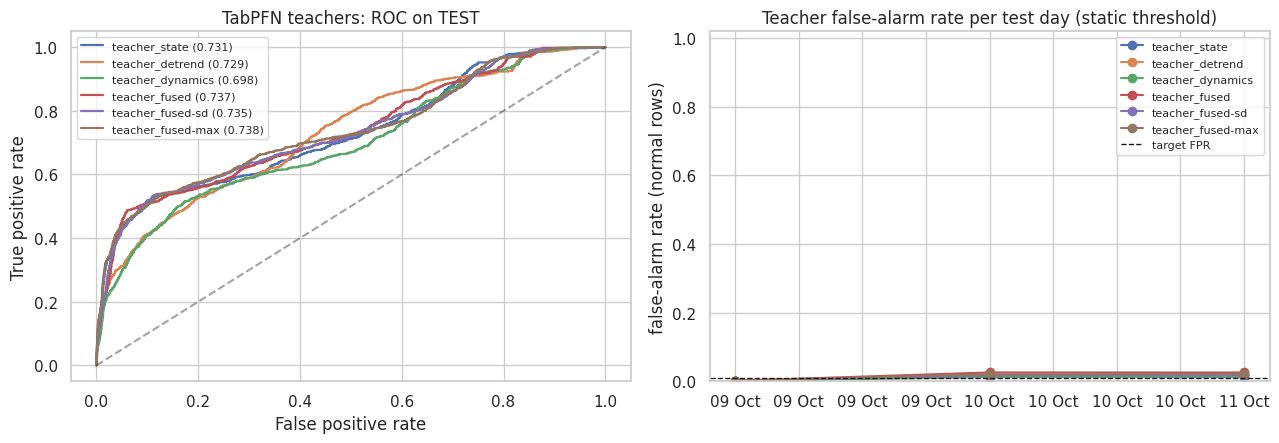

In [15]:
tt, tc = teacher_files["test"], teacher_files["cal"]
teacher_variants = [f"teacher_{v}" for v in views] + [f"teacher_{f}" for f in FUSIONS] + ["teacher_fused-max"]

phase = np.full(len(tt), "normal", dtype=object)
for seg in segments.itertuples(index=False):
    inside = tt["timestamp"].between(seg.start, seg.end).to_numpy()
    since = (tt["timestamp"] - seg.start).dt.total_seconds().to_numpy()
    phase[inside] = np.where(since[inside] < EVAL_CONFIG["onset_s"], "onset", "sustained")

rows = []
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    pred = tt[col].to_numpy() >= thr
    rows.append({"teacher": col, "threshold": thr, **point_metrics(y_test, tt[col], thr),
                 "recall_onset": pred[phase == "onset"].mean(), "recall_sustained": pred[phase == "sustained"].mean()})
display(pd.DataFrame(rows).set_index("teacher").round(4))

seed_auc = pd.DataFrame([{"view": v, "seed": s, "roc_auc": roc_auc_score(y_test, tt[f"teacher_{v}_seed_{s}"])}
                         for v in views for s in seeds])
display(seed_auc.groupby("view")["roc_auc"].agg(["mean", "std", "min", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for col in teacher_variants:
    f, t_, _ = roc_curve(y_test, tt[col])
    axes[0].plot(f, t_, lw=1.6, label=f"{col} ({roc_auc_score(y_test, tt[col]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="TabPFN teachers: ROC on TEST")
axes[0].legend(fontsize=8)
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    daily = daily_false_alarm_rate(tt["timestamp"], y_test, tt[col] >= thr)
    axes[1].plot(pd.to_datetime(daily.index), daily.values, marker="o", label=col)
axes[1].axhline(EVAL_CONFIG["target_fpr"], color="k", ls="--", lw=1, label="target FPR")
axes[1].set(ylabel="false-alarm rate (normal rows)", title="Teacher false-alarm rate per test day (static threshold)", ylim=(0, 1.02))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "teacher_roc_daily")
plt.show()

## **Part D — Gaussian mixture density baseline (same features, scaler, calibration and fusion)**

One full-covariance GMM per view is fitted on a FIT subsample (every 20 s), with *k* chosen by BIC over {4, …, 128} and the score = −log p. Scores are calibrated (robust z against CAL) and fused **exactly like the teacher**, so `TabPFN <x> − GMM <x>` isolates what the foundation-model density adds.

In [16]:
%%time
gmm_raw, gmm_rows, bic_rows = {}, [], []
for view in views:
    X_fit = scaled(view, fit_df)[::GMM_CONFIG["fit_stride"]]
    best = None
    for k in GMM_CONFIG["components_grid"]:
        t0 = time.perf_counter()
        gmm = GaussianMixture(k, covariance_type=GMM_CONFIG["covariance"], reg_covar=GMM_CONFIG["reg_covar"],
                              random_state=GMM_CONFIG["seed"]).fit(X_fit)
        bic = gmm.bic(X_fit)
        bic_rows.append({"view": view, "k": k, "bic": bic, "fit_seconds": time.perf_counter() - t0})
        if best is None or bic < best[0]:
            best = (bic, k, gmm)
    _, k, gmm = best
    if k == max(GMM_CONFIG["components_grid"]):
        print(f"WARNING: GMM {view}: BIC still prefers the largest k = {k}; consider extending the grid.")
    X_test_view = scaled(view, test_df)
    t0 = time.perf_counter()
    test_scores = -gmm.score_samples(X_test_view)
    ms_per_row = 1000 * (time.perf_counter() - t0) / len(X_test_view)
    gmm_raw[view] = {"cal": -gmm.score_samples(scaled(view, cal_df)), "test": test_scores}
    thr = threshold_from_calibration(gmm_raw[view]["cal"], EVAL_CONFIG["target_fpr"])
    point = point_metrics(y_test, gmm_raw[view]["test"], thr)
    gmm_rows.append({"view": view, "k": k, "n_features": X_fit.shape[1], "ms_per_row_batched": ms_per_row, **point})
    print(f"GMM {view:9s} k={k:2d}  AUC={point['roc_auc']:.4f}  test FPR={point['test_fpr']:.3f}  recall={point['recall']:.3f}")

gmm_out = {split: add_fusions({v: robust_z(gmm_raw[v][split], gmm_raw[v]["cal"]) for v in views}) for split in SPLITS}
for name in gmm_out["test"]:
    for split in SPLITS:
        pd.DataFrame({"score": gmm_out[split][name]}).to_parquet(RUN_DIR / f"gmm_{name}_{split}.parquet", index=False)
pd.DataFrame(gmm_rows).to_csv(RUN_DIR / "gmm_summary.csv", index=False)
pd.DataFrame(bic_rows).to_csv(RUN_DIR / "gmm_bic.csv", index=False)
display(pd.DataFrame(gmm_rows).set_index("view").round(4))
display(pd.DataFrame(bic_rows).pivot(index="k", columns="view", values="bic").round(0))

GMM state     k=48  AUC=0.7092  test FPR=0.012  recall=0.148
GMM detrend   k=64  AUC=0.7502  test FPR=0.009  recall=0.050
GMM dynamics  k=64  AUC=0.6861  test FPR=0.009  recall=0.049


,k,n_features,ms_per_row_batched,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy
view,,,,,,,,,,
state,48,54,0.0027,0.7092,0.2418,0.4408,0.1480,0.2216,0.0116,0.9394
detrend,64,35,0.0024,0.7502,0.1926,0.2551,0.0497,0.0831,0.0090,0.9362
dynamics,64,35,0.0023,0.6861,0.1220,0.2539,0.0487,0.0817,0.0088,0.9362


view,detrend,dynamics,state
k,,,
4,171372.0,308870.0,-906179.0
8,-1239111.0,-611978.0,-2774022.0
16,-1618703.0,-1172935.0,-3985830.0
32,-2241469.0,-1652589.0,-4145333.0
48,-2386516.0,-1721663.0,-4494385.0
64,-2411193.0,-1757290.0,-4467941.0
96,-2404377.0,-1687794.0,-4402523.0
128,-2259581.0,-1602408.0,-4439994.0


CPU times: user 2h 56min 2s, sys: 9.08 s, total: 2h 56min 11s
Wall time: 13min 55s


## **E. Evaluation: every table rebuilt from the saved files**

This section reloads only the saved score files. For each family (TabPFN and GMM) it evaluates: **fused (primary)**, fused-sd, fused-max, state, detrend and dynamics. Two thresholds are applied to every method:
- **static**: the CAL 1% quantile;
- **adaptive**: the score normalised by its trailing-24 h median/IQR (label-free), then thresholded at the CAL quantile of the normalised score.

In [17]:
cfg = json.loads((RUN_DIR / "config.json").read_text())
ecfg = cfg["eval_config"]
target_fpr = ecfg["target_fpr"]
stride_s = cfg["teacher_config"]["test_stride"]
ev_test = pd.read_parquet(TEACHER_DIR / "teacher_test.parquet")
ev_cal = pd.read_parquet(TEACHER_DIR / "teacher_cal.parquet")
ev_segments = pd.read_csv(TEACHER_DIR / "attack_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
y_eval = ev_test["is_attack"].to_numpy().astype(int)
ts_eval = ev_test["timestamp"]
view_names = list(json.loads((TEACHER_DIR / "features.json").read_text())["views"])
GROUPS = [ecfg["primary"]] + [f for f in ecfg["fusions"] if f != ecfg["primary"]] + ["fused-max"] + view_names

METHODS = {}
for family in ["TabPFN", "GMM"]:
    for g in GROUPS:
        if family == "TabPFN":
            METHODS[f"TabPFN {g}"] = (ev_test[f"teacher_{g}"].to_numpy(), ev_cal[f"teacher_{g}"].to_numpy())
        else:
            METHODS[f"GMM {g}"] = (pd.read_parquet(RUN_DIR / f"gmm_{g}_test.parquet")["score"].to_numpy(),
                                   pd.read_parquet(RUN_DIR / f"gmm_{g}_cal.parquet")["score"].to_numpy())
names = list(METHODS)
PRIMARY = {"TabPFN": f"TabPFN {ecfg['primary']}", "GMM": f"GMM {ecfg['primary']}"}
CORE = [f"{fam} {g}" for g in [ecfg["primary"], "fused-sd"] for fam in ["TabPFN", "GMM"] if f"{fam} {g}" in METHODS]
score_matrix = {m: METHODS[m][0] for m in names}
THRESHOLDS = {m: threshold_from_calibration(cal, target_fpr) for m, (_, cal) in METHODS.items()}

ADAPTIVE = {}
for m, (test_s, cal_s) in METHODS.items():
    z_cal, z_test = adaptive_normalise(cal_s, test_s, stride_s, ecfg)
    ADAPTIVE[m] = (z_test, threshold_from_calibration(z_cal, target_fpr))

phase_eval = np.full(len(ev_test), "normal", dtype=object)
for seg in ev_segments.itertuples(index=False):
    inside = ts_eval.between(seg.start, seg.end).to_numpy()
    since = (ts_eval - seg.start).dt.total_seconds().to_numpy()
    phase_eval[inside] = np.where(since[inside] < ecfg["onset_s"], "onset", "sustained")

family_color = {"TabPFN": "#1d3557", "GMM": "#e76f51"}
method_colors = dict(zip(names, sns.color_palette("tab20", len(names))))
print(f"Run {cfg['run_id']} | run {cfg['run_fingerprint']} | teacher {cfg['teacher_fingerprint']}")
print(f"TEST rows: {len(y_eval):,} ({y_eval.sum():,} attack, {y_eval.mean():.1%}) | events: {len(ev_segments)} | target FPR {target_fpr}")
print(f"Methods ({len(names)}): {names}")

Run WADi_A1_2017_full_pipeline_v1 | run 134969fe8e | teacher 7b5a98dccd
TEST rows: 17,281 (1,007 attack, 5.8%) | events: 14 | target FPR 0.01
Methods (12): ['TabPFN fused', 'TabPFN fused-sd', 'TabPFN fused-max', 'TabPFN state', 'TabPFN detrend', 'TabPFN dynamics', 'GMM fused', 'GMM fused-sd', 'GMM fused-max', 'GMM state', 'GMM detrend', 'GMM dynamics']


### **E1. Point-wise and event-wise results: static vs. adaptive threshold**

`recall_onset` and `recall_sustained` split attack rows into the first 5 min of each attack and the rest.

In [18]:
rows, per_event_tables = [], {}
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]),
                                "adaptive": ADAPTIVE[method]}.items():
        pred = scores >= thr
        point = point_metrics(y_eval, np.nan_to_num(scores, nan=-np.inf), thr)
        event, per_event = event_metrics(ts_eval, y_eval, pred, ev_segments)
        per_event_tables[(method, mode)] = per_event
        rows.append({"method": method, "threshold_mode": mode, "threshold": thr, **point, **event,
                     "recall_onset": pred[phase_eval == "onset"].mean(),
                     "recall_sustained": pred[phase_eval == "sustained"].mean()})
main_results = pd.DataFrame(rows)
main_results.insert(0, "run_fingerprint", cfg["run_fingerprint"])
main_results.to_csv(RUN_DIR / "results_main.csv", index=False)
show_cols = ["roc_auc", "average_precision", "test_fpr", "recall", "recall_onset", "recall_sustained", "precision",
             "f1", "attacks_detected", "false_alarm_episodes", "composite_f1", "median_ttd_s"]
for mode in ["static", "adaptive"]:
    print(f"--- {mode} threshold ---")
    display(main_results[main_results["threshold_mode"] == mode].set_index("method")[show_cols].round(4))

--- static threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.7368,0.2951,0.0226,0.2493,0.4128,0.1459,0.4055,0.3087,8,80,0.4744,7.5
TabPFN fused-sd,0.7351,0.2980,0.0146,0.2066,0.2974,0.1491,0.4664,0.2863,8,72,0.5136,25.0
TabPFN fused-max,0.7383,0.3260,0.0184,0.3088,0.3128,0.3063,0.5098,0.3847,8,100,0.5389,20.0
TabPFN state,0.7312,0.3210,0.0160,0.3019,0.3077,0.2982,0.5390,0.3870,8,109,0.5547,25.0
TabPFN detrend,0.7293,0.2561,0.0162,0.2175,0.3769,0.1167,0.4544,0.2942,8,45,0.5062,7.5
TabPFN dynamics,0.6984,0.2098,0.0106,0.1271,0.2462,0.0519,0.4267,0.1959,8,52,0.4885,25.0
GMM fused,0.7552,0.2248,0.0155,0.1241,0.1821,0.0875,0.3307,0.1805,8,53,0.4189,175.0
GMM fused-sd,0.7462,0.2322,0.0120,0.1351,0.1821,0.1053,0.4109,0.2033,9,36,0.5013,40.0
GMM fused-max,0.7477,0.2088,0.0133,0.1013,0.1564,0.0665,0.3208,0.1540,7,53,0.3908,170.0


--- adaptive threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.7267,0.2710,0.0442,0.4320,0.4564,0.4165,0.3766,0.4024,8,104,0.4540,3.0
TabPFN fused-sd,0.7265,0.2658,0.0385,0.3803,0.4256,0.3517,0.3792,0.3798,8,93,0.4559,3.0
TabPFN fused-max,0.7313,0.3134,0.0342,0.3823,0.3744,0.3874,0.4091,0.3953,9,126,0.5000,9.0
TabPFN state,0.7286,0.3066,0.0131,0.2363,0.2974,0.1977,0.5265,0.3263,8,82,0.5481,25.0
TabPFN detrend,0.7243,0.2541,0.0377,0.2969,0.4513,0.1994,0.3275,0.3115,8,105,0.4164,3.0
TabPFN dynamics,0.6735,0.1993,0.0329,0.2433,0.3949,0.1475,0.3137,0.2740,8,126,0.4050,3.0
GMM fused,0.7569,0.2303,0.0222,0.1956,0.2487,0.1621,0.3524,0.2516,8,60,0.4360,30.0
GMM fused-sd,0.7450,0.2374,0.0155,0.1778,0.2051,0.1605,0.4153,0.2490,10,54,0.5252,100.0
GMM fused-max,0.7481,0.2199,0.0171,0.1599,0.1692,0.1540,0.3667,0.2227,8,52,0.4468,110.0


#### **Confusion matrices: real vs. predicted (core methods)**

Rows are the **real** label and columns are the **predicted** label, on TEST rows (1 every 10 s). Each cell shows the count and the share of its real class:
- **Normal → Attack** = the test FPR.
- **Attack → Attack** = the recall.

TN   FP   FN   TP  attacks_detected  \
method           threshold_mode                                           
TabPFN fused     static          15906  368  756  251                 8   
                 adaptive        15554  720  572  435                 8   
TabPFN fused-sd  static          16036  238  799  208                 8   
                 adaptive        15647  627  624  383                 8   
TabPFN fused-max static          15975  299  696  311                 8   
                 adaptive        15718  556  622  385                 9   
TabPFN state     static          16014  260  703  304                 8   
                 adaptive        16060  214  769  238                 8   
TabPFN detrend   static          16011  263  788  219                 8   
                 adaptive        15660  614  708  299                 8   
TabPFN dynamics  static          16102  172  879  128                 8   
                 adaptive        15738  536  762  245                 8   
GMM fused        static          16021  253  882  125                 8   
                 adaptive        15912  362  810  197                 8   
GMM fused-sd     static          16079  195  871  136                 9   
                 adaptive        16022  252  828  179                10   
GMM fused-max    static          16058  216  905  102                 7   
                 adaptive        15996  278  846  161                 8   
GMM state        static          16085  189  858  149                 8   
                 adaptive        16003  271  816  191                10   
GMM detrend      static          16128  146  957   50                 5   
                 adaptive        16064  210  891  116                 6   
GMM dynamics     static          16130  144  958   49                 5   
                 adaptive        15962  312  929   78                 6   

                                 false_alarm_episodes  
method           threshold_mode                        
TabPFN fused     static                            80  
                 adaptive                         104  
TabPFN fused-sd  static                            72  
                 adaptive                          93  
TabPFN fused-max static                           100  
                 adaptive                         126  
TabPFN state     static                           109  
                 adaptive                          82  
TabPFN detrend   static                            45  
                 adaptive                         105  
TabPFN dynamics  static                            52  
                 adaptive                         126  
GMM fused        static                            53  
                 adaptive                          60  
GMM fused-sd     static                            36  
                 adaptive                          54  
GMM fused-max    static                            53  
                 adaptive                          52  
GMM state        static                            36  
                 adaptive                          69  
GMM detrend      static                            30  
                 adaptive                          37  
GMM dynamics     static                            52  
                 adaptive                          76

figure saved: output-figures/confusion_matrices_wadi2017_v1.png


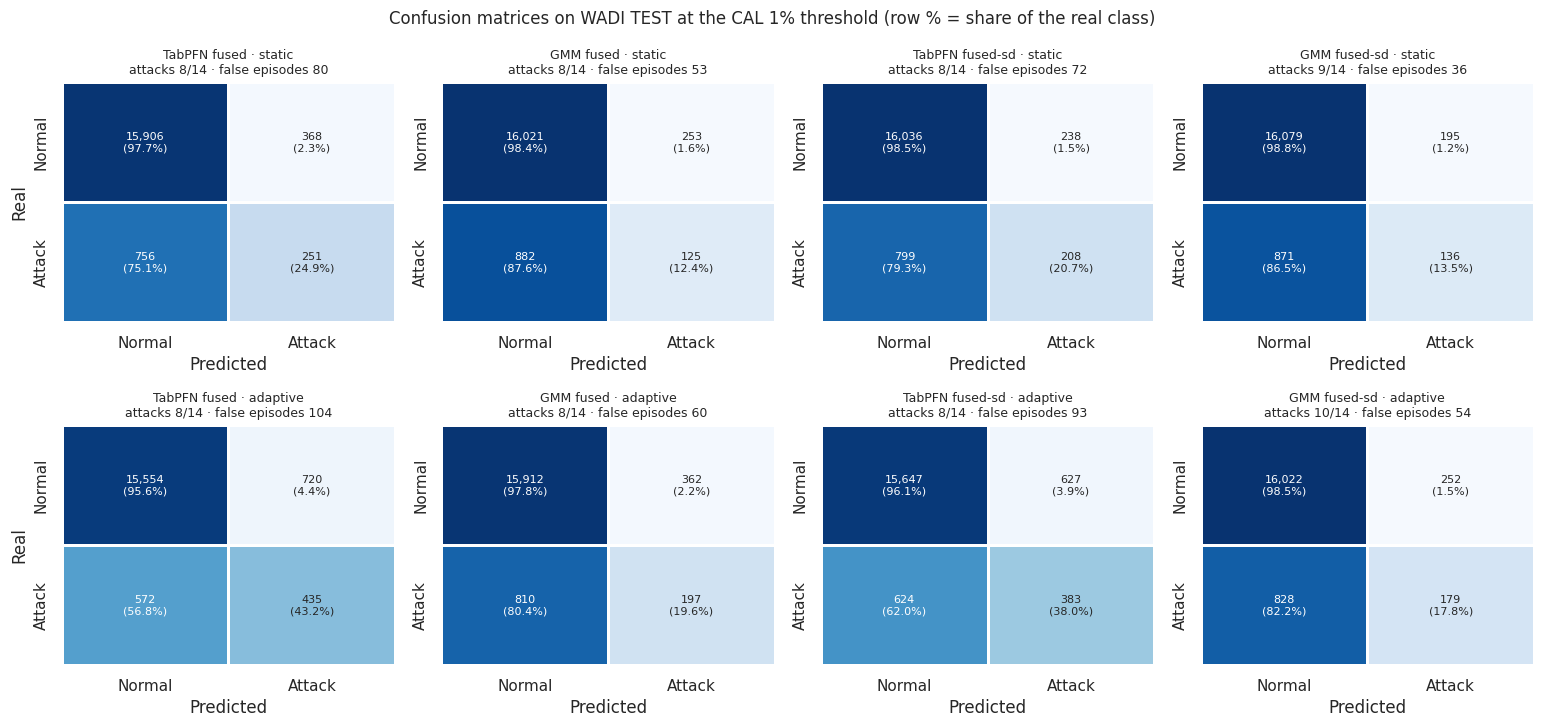

In [19]:
cm_rows = []
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]), "adaptive": ADAPTIVE[method]}.items():
        tn, fp, fn, tp = confusion_matrix(y_eval, (scores >= thr).astype(int), labels=[0, 1]).ravel()
        r = main_results[(main_results["method"] == method) & (main_results["threshold_mode"] == mode)].iloc[0]
        cm_rows.append({"method": method, "threshold_mode": mode, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                        "attacks_detected": int(r["attacks_detected"]), "false_alarm_episodes": int(r["false_alarm_episodes"])})
confusion_table = pd.DataFrame(cm_rows)
confusion_table.to_csv(RUN_DIR / "results_confusion.csv", index=False)
display(confusion_table.set_index(["method", "threshold_mode"]))

fig, axes = plt.subplots(2, len(CORE), figsize=(3.9 * len(CORE), 7.4), squeeze=False)
for row_i, mode in enumerate(["static", "adaptive"]):
    for ax, m in zip(axes[row_i], CORE):
        r = confusion_table[(confusion_table["method"] == m) & (confusion_table["threshold_mode"] == mode)].iloc[0]
        counts = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        share = counts / counts.sum(axis=1, keepdims=True)
        labels = np.array([[f"{c:,}\n({p:.1%})" for c, p in zip(cr, pr)] for cr, pr in zip(counts, share)])
        sns.heatmap(share, annot=labels, fmt="", annot_kws={"size": 8}, cmap="Blues", vmin=0, vmax=1, cbar=False,
                    linewidths=1, xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=ax)
        ax.grid(False)
        ax.set(xlabel="Predicted", ylabel="Real" if ax is axes[row_i][0] else "")
        ax.set_title(f"{m} · {mode}\nattacks {r.attacks_detected}/{len(ev_segments)} · false episodes {r.false_alarm_episodes}", fontsize=9)
fig.suptitle(f"Confusion matrices on WADI TEST at the CAL {target_fpr:.0%} threshold (row % = share of the real class)", fontsize=12)
plt.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

### **E2. Several operating points (static threshold)**

In [20]:
grid_rows = []
for fpr_target in ecfg["fpr_grid"]:
    for method, (scores, cal) in METHODS.items():
        thr = threshold_from_calibration(cal, fpr_target)
        point = point_metrics(y_eval, scores, thr)
        event, _ = event_metrics(ts_eval, y_eval, scores >= thr, ev_segments)
        grid_rows.append({"target_fpr": fpr_target, "method": method, "test_fpr": point["test_fpr"],
                          "precision": point["precision"], "recall": point["recall"], "f1": point["f1"],
                          "attacks_detected": f"{event['attacks_detected']}/{event['attacks_total']}",
                          "composite_f1": event["composite_f1"], "median_ttd_s": event["median_ttd_s"]})
operating_points = pd.DataFrame(grid_rows)
operating_points.to_csv(RUN_DIR / "results_operating_points.csv", index=False)
display(operating_points.pivot(index="method", columns="target_fpr", values=["test_fpr", "recall", "attacks_detected"]).loc[names])

test_fpr                                  recall            \
target_fpr           0.005     0.010     0.020     0.050     0.005     0.010   
method                                                                         
TabPFN fused      0.015976  0.022613  0.028942  0.044119  0.217478  0.249255   
TabPFN fused-sd   0.011552  0.014625  0.022428   0.04117  0.173784  0.206554   
TabPFN fused-max  0.012843  0.018373   0.02716  0.043566  0.230387  0.308838   
TabPFN state       0.01063  0.015976  0.026177   0.04584  0.215492  0.301887   
TabPFN detrend    0.011737  0.016161  0.025869  0.050879  0.187686  0.217478   
TabPFN dynamics   0.008971  0.010569  0.013273  0.027529  0.105263   0.12711   
GMM fused         0.008111  0.015546  0.022428  0.040924  0.098312  0.124131   
GMM fused-sd      0.008418  0.011982  0.021384  0.043013  0.097319  0.135055   
GMM fused-max     0.007497  0.013273  0.021322  0.038282  0.090367  0.101291   
GMM state         0.008234  0.011614  0.029126  0.052476  0.097319  0.147964   
GMM detrend       0.004793  0.008971  0.013457  0.036746  0.013903  0.049652   
GMM dynamics      0.004424  0.008848  0.021814  0.042153   0.02284  0.048659   

                                     attacks_detected                      
target_fpr           0.020     0.050            0.005 0.010  0.020  0.050  
method                                                                     
TabPFN fused      0.309831  0.421053             8/14  8/14   8/14   8/14  
TabPFN fused-sd   0.285998   0.39424             8/14  8/14   8/14   8/14  
TabPFN fused-max  0.354518  0.424032             8/14  8/14   9/14  10/14  
TabPFN state      0.345581  0.422046             8/14  8/14   9/14  10/14  
TabPFN detrend    0.259186  0.311817             7/14  8/14   8/14   8/14  
TabPFN dynamics   0.167825  0.232373             7/14  8/14   8/14   8/14  
GMM fused         0.197617  0.306852             5/14  8/14   9/14  11/14  
GMM fused-sd      0.217478  0.351539             6/14  9/14  10/14  11/14  
GMM fused-max     0.171797  0.276068             5/14  7/14   8/14  11/14  
GMM state         0.274081  0.424032             7/14  8/14  11/14  12/14  
GMM detrend       0.114201  0.272095             2/14  5/14   7/14  11/14  
GMM dynamics      0.084409  0.145978             3/14  5/14   7/14  11/14

### **E3. Uncertainty: two bootstraps on the same replicates, and seeds**

- **Row-block bootstrap** (circular, 1 h blocks): keeps the autocorrelation intact. It treats the attack schedule as fixed.
- **Event bootstrap**: resamples the 14 attacks and the 1 h normal blocks separately, so it also captures *which* attacks happened. With so few attacks, this is the more honest interval, and the one used for the conclusions.

Every method is scored on the same replicate indices, so paired differences (§F2) come straight from these replicates.

In [21]:
%%time
rng = np.random.default_rng(ecfg["bootstrap_seed"])
block = ecfg["bootstrap_block_rows"]
attack_units = [np.arange(a, b) for a, b in contiguous_runs(y_eval == 1)]
normal_units = [np.arange(a, b)[i:i + block] for a, b in contiguous_runs(y_eval == 0) for i in range(0, b - a, block)]
print(f"Event bootstrap units: {len(attack_units)} attacks, {len(normal_units)} normal blocks")

boot = {"block": [], "event": []}
for _ in range(ecfg["bootstrap_repeats"]):
    for kind, idx in [("block", block_bootstrap_indices(len(y_eval), block, rng)),
                      ("event", event_bootstrap_indices(attack_units, normal_units, rng))]:
        yb = y_eval[idx]
        if yb.min() == yb.max():
            continue
        rec = {}
        for m in names:
            rec[f"auc|{m}"] = roc_auc_score(yb, score_matrix[m][idx])
            rec[f"ap|{m}"] = average_precision_score(yb, score_matrix[m][idx])
        boot[kind].append(rec)
boot = {k: pd.DataFrame(v) for k, v in boot.items()}
for kind, frame in boot.items():
    frame.to_parquet(RUN_DIR / f"bootstrap_replicates_{kind}.parquet", index=False)

ci_rows = []
for m in names:
    for metric, key, point in [("ROC-AUC", "auc", roc_auc_score(y_eval, score_matrix[m])),
                               ("Average precision", "ap", average_precision_score(y_eval, score_matrix[m]))]:
        row = {"method": m, "metric": metric, "estimate": point}
        for kind in boot:
            row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(boot[kind][f"{key}|{m}"], [0.025, 0.975])
        ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RUN_DIR / "results_bootstrap_ci.csv", index=False)
print({k: len(v) for k, v in boot.items()}, "replicates")
display(ci_table.set_index(["method", "metric"]).round(4))

seed_cols = [c for c in ev_test.columns if "_seed_" in c]
seed_table = pd.DataFrame([
    {"view": c.split("_seed_")[0].replace("teacher_", ""), "seed": c.split("_seed_")[1],
     "roc_auc": roc_auc_score(y_eval, ev_test[c]), "average_precision": average_precision_score(y_eval, ev_test[c])}
    for c in seed_cols
])
seed_table.to_csv(RUN_DIR / "results_teacher_seeds.csv", index=False)
display(seed_table.groupby("view")[["roc_auc", "average_precision"]].agg(["mean", "std", "min", "max"]).round(4))

Event bootstrap units: 14 attacks, 55 normal blocks
{'block': 1000, 'event': 1000} replicates


estimate  block_ci_low  block_ci_high  \
method           metric                                                     
TabPFN fused     ROC-AUC              0.7368        0.5184         0.8664   
                 Average precision    0.2951        0.0336         0.4730   
TabPFN fused-sd  ROC-AUC              0.7351        0.5119         0.8704   
                 Average precision    0.2980        0.0322         0.4832   
TabPFN fused-max ROC-AUC              0.7383        0.5119         0.8739   
                 Average precision    0.3260        0.0298         0.5133   
TabPFN state     ROC-AUC              0.7312        0.5131         0.8690   
                 Average precision    0.3210        0.0295         0.5162   
TabPFN detrend   ROC-AUC              0.7293        0.5403         0.8436   
                 Average precision    0.2561        0.0348         0.4215   
TabPFN dynamics  ROC-AUC              0.6984        0.4909         0.8262   
                 Average precision    0.2098        0.0392         0.3717   
GMM fused        ROC-AUC              0.7552        0.5577         0.8911   
                 Average precision    0.2248        0.0462         0.4038   
GMM fused-sd     ROC-AUC              0.7462        0.5470         0.8829   
                 Average precision    0.2322        0.0488         0.4243   
GMM fused-max    ROC-AUC              0.7477        0.5562         0.8812   
                 Average precision    0.2088        0.0448         0.3784   
GMM state        ROC-AUC              0.7092        0.4518         0.8848   
                 Average precision    0.2418        0.0548         0.4495   
GMM detrend      ROC-AUC              0.7502        0.5756         0.8645   
                 Average precision    0.1926        0.0417         0.3408   
GMM dynamics     ROC-AUC              0.6861        0.5361         0.7925   
                 Average precision    0.1220        0.0304         0.2391   

                                    event_ci_low  event_ci_high  
method           metric                                          
TabPFN fused     ROC-AUC                  0.5747         0.8732  
                 Average precision        0.1323         0.5337  
TabPFN fused-sd  ROC-AUC                  0.5718         0.8734  
                 Average precision        0.1300         0.5437  
TabPFN fused-max ROC-AUC                  0.5758         0.8777  
                 Average precision        0.1418         0.5773  
TabPFN state     ROC-AUC                  0.5772         0.8732  
                 Average precision        0.1343         0.5783  
TabPFN detrend   ROC-AUC                  0.5838         0.8563  
                 Average precision        0.1140         0.4788  
TabPFN dynamics  ROC-AUC                  0.5461         0.8348  
                 Average precision        0.1051         0.3761  
GMM fused        ROC-AUC                  0.6035         0.8984  
                 Average precision        0.1128         0.4314  
GMM fused-sd     ROC-AUC                  0.5878         0.8907  
                 Average precision        0.1134         0.4473  
GMM fused-max    ROC-AUC                  0.6008         0.8910  
                 Average precision        0.1078         0.4023  
GMM state        ROC-AUC                  0.4943         0.9011  
                 Average precision        0.1079         0.4738  
GMM detrend      ROC-AUC                  0.6261         0.8741  
                 Average precision        0.1056         0.3485  
GMM dynamics     ROC-AUC                  0.5752         0.8041  
                 Average precision        0.0752         0.2117

roc_auc                         average_precision                  \
            mean     std     min     max              mean     std     min   
view                                                                         
detrend   0.7290  0.0050  0.7246  0.7344            0.2554  0.0013  0.2540   
dynamics  0.6979  0.0042  0.6953  0.7027            0.2076  0.0089  0.1997   
state     0.7355  0.0219  0.7113  0.7539            0.3077  0.0406  0.2612   

                  
             max  
view              
detrend   0.2565  
dynamics  0.2172  
state     0.3364

CPU times: user 1min 35s, sys: 67.9 ms, total: 1min 35s
Wall time: 1min 35s


figure saved: output-figures/auc_ap_ci_all_methods_wadi2017_v1.png


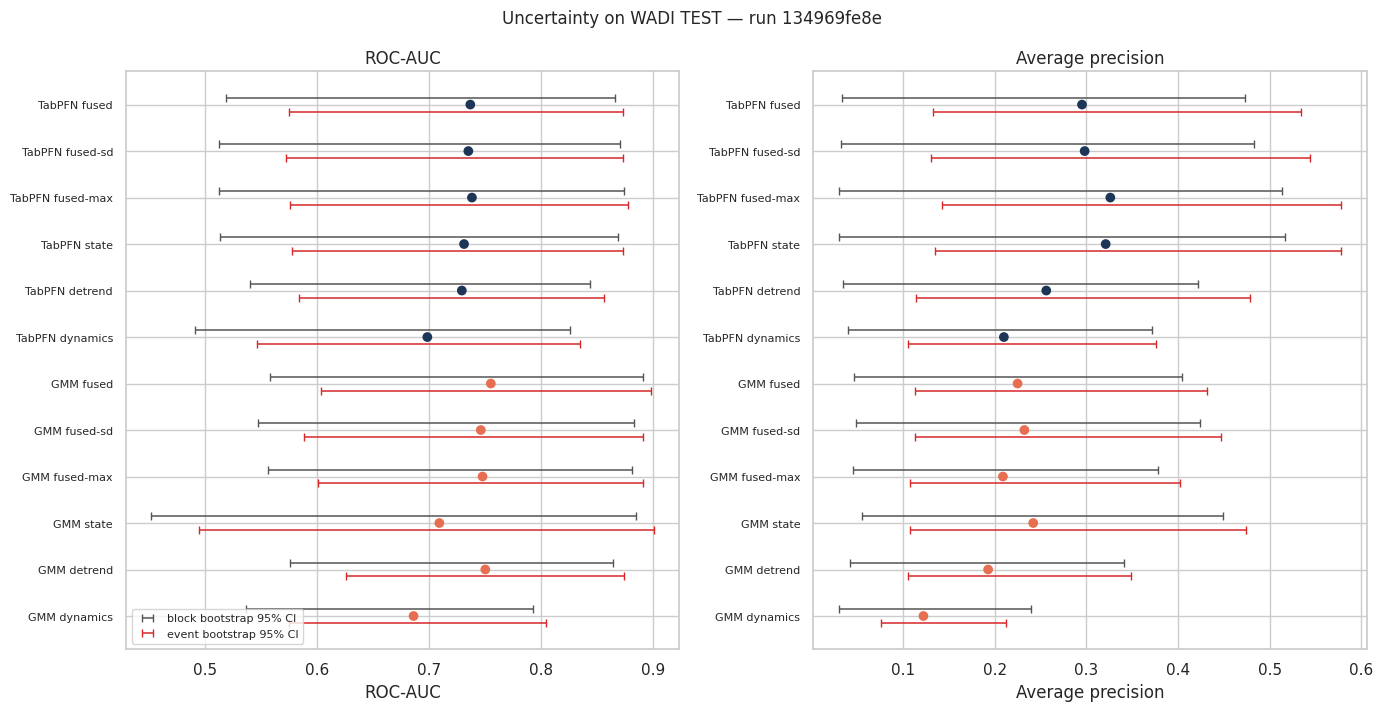

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(names) + 2.2))
for ax, metric in zip(axes, ["ROC-AUC", "Average precision"]):
    view = ci_table[ci_table["metric"] == metric].set_index("method").loc[names]
    ypos = np.arange(len(view))
    for off, kind, color in [(-0.15, "block", "#555"), (0.15, "event", "#d62828")]:
        ax.errorbar(view["estimate"], ypos + off, xerr=[view["estimate"] - view[f"{kind}_ci_low"],
                    view[f"{kind}_ci_high"] - view["estimate"]], fmt="none", ecolor=color, capsize=3, lw=1.1,
                    label=f"{kind} bootstrap 95% CI")
    ax.scatter(view["estimate"], ypos, c=[family_color[m.split()[0]] for m in names], s=36, zorder=3)
    ax.set(yticks=ypos, xlabel=metric, title=metric)
    ax.set_yticklabels(names, fontsize=8)
    ax.invert_yaxis()
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"Uncertainty on WADI TEST — run {cfg['run_fingerprint']}", fontsize=12)
plt.tight_layout()
save_fig(fig, "auc_ap_ci_all_methods")
plt.show()

### **E4. Per-attack detection (static threshold)**

figure saved: output-figures/per_attack_coverage_wadi2017_v1.png


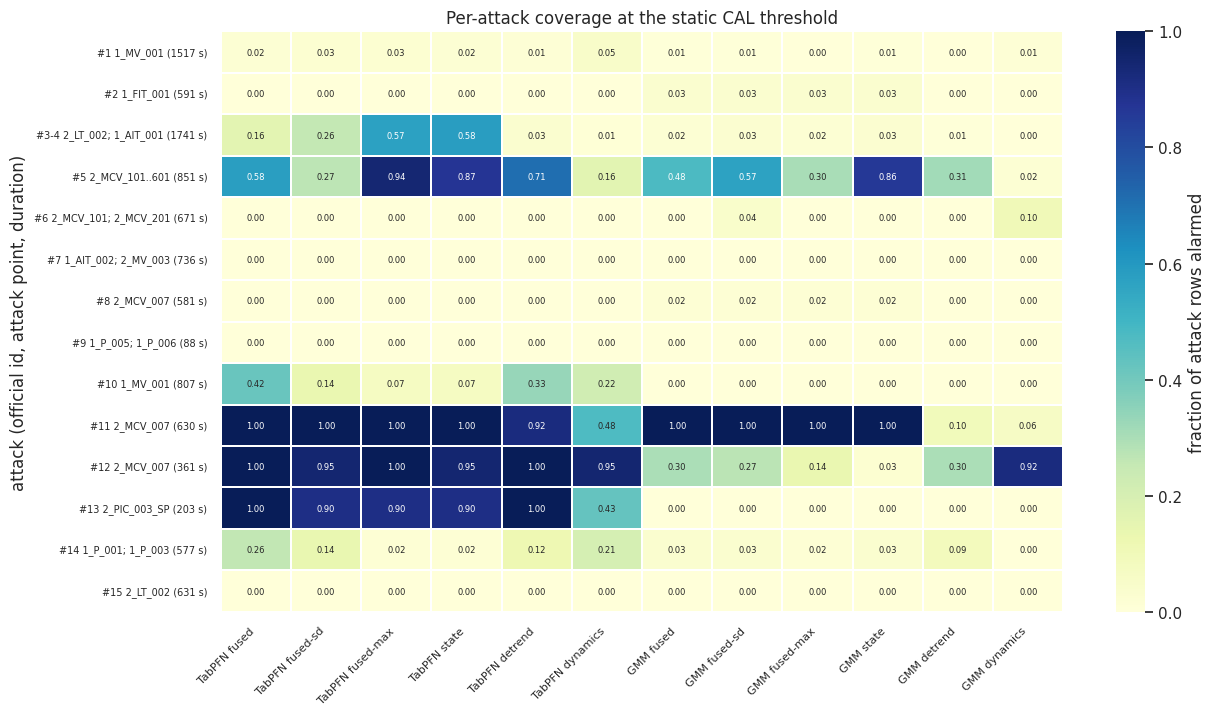

In [23]:
event_view = per_event_tables[(names[0], "static")][["segment", "attack_id", "attack_point", "start", "duration_s"]].copy()
for m in names:
    event_view[f"{m} detected"] = per_event_tables[(m, "static")]["detected"]
    event_view[f"{m} TTD (s)"] = per_event_tables[(m, "static")]["time_to_detect_s"]
event_view.to_csv(RUN_DIR / "results_per_attack.csv", index=False)

heat = pd.DataFrame({m: per_event_tables[(m, "static")]["fraction_alarmed"].to_numpy() for m in names})
heat.index = [f"#{r.attack_id} {r.attack_point} ({int(r.duration_s)} s)" for r in event_view.itertuples()]
fig, ax = plt.subplots(figsize=(0.75 * len(names) + 4, 0.38 * len(heat) + 2))
sns.heatmap(heat, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.3,
            cbar_kws={"label": "fraction of attack rows alarmed"}, ax=ax)
ax.set(xlabel="", ylabel="attack (official id, attack point, duration)", title="Per-attack coverage at the static CAL threshold")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=7)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
save_fig(fig, "per_attack_coverage")
plt.show()

### **E5. Curves, score distributions and the score timeline (core methods)**

figure saved: output-figures/roc_pr_core_wadi2017_v1.png


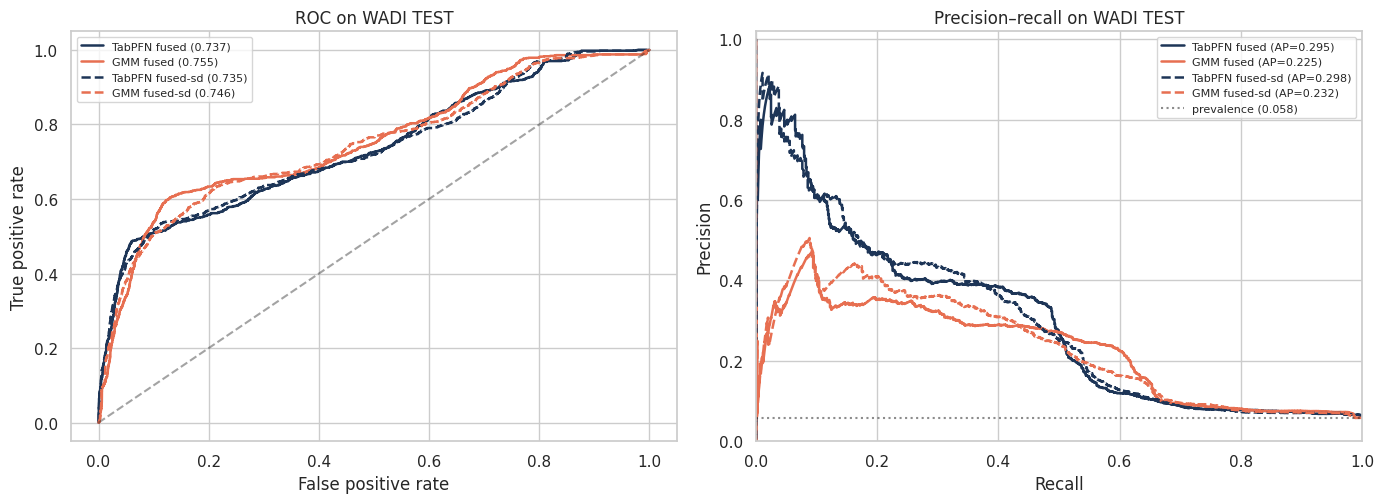

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for m in CORE:
    s = score_matrix[m]
    ls = "-" if m in PRIMARY.values() else "--"
    f, t_, _ = roc_curve(y_eval, s)
    axes[0].plot(f, t_, lw=1.8, ls=ls, color=family_color[m.split()[0]], label=f"{m} ({roc_auc_score(y_eval, s):.3f})")
    p, r, _ = precision_recall_curve(y_eval, s)
    axes[1].plot(r, p, lw=1.8, ls=ls, color=family_color[m.split()[0]], label=f"{m} (AP={average_precision_score(y_eval, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC on WADI TEST")
axes[1].axhline(y_eval.mean(), color="k", ls=":", alpha=0.5, label=f"prevalence ({y_eval.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall on WADI TEST", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "roc_pr_core")
plt.show()

figure saved: output-figures/score_distributions_wadi2017_v1.png


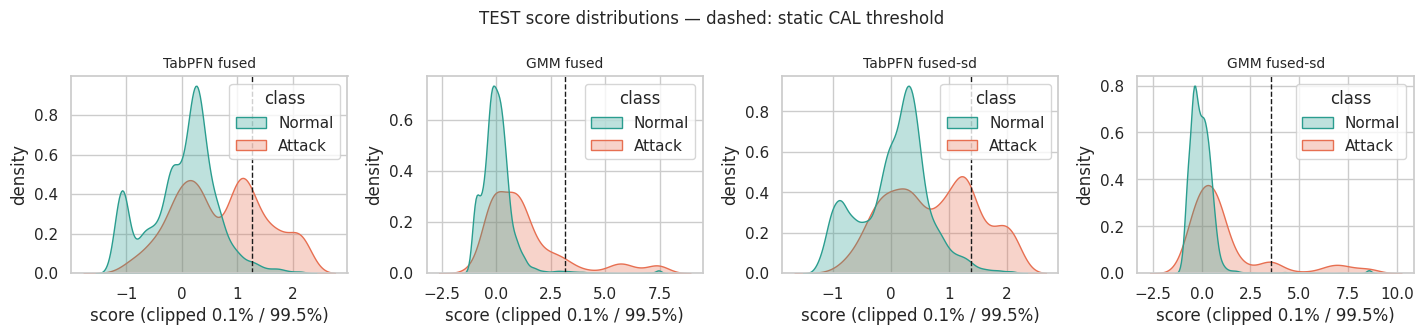

In [25]:
fig, axes = plt.subplots(1, len(CORE), figsize=(3.6 * len(CORE), 3.4), squeeze=False)
for ax, m in zip(axes[0], CORE):
    s = score_matrix[m]
    lo, hi = np.quantile(s, [0.001, 0.995])
    frame = pd.DataFrame({"score": np.clip(s, lo, hi), "class": np.where(y_eval == 1, "Attack", "Normal")})
    sns.kdeplot(data=frame, x="score", hue="class", hue_order=["Normal", "Attack"], common_norm=False,
                fill=True, alpha=0.3, palette={"Normal": "#2a9d8f", "Attack": "#e76f51"}, warn_singular=False, ax=ax)
    ax.axvline(THRESHOLDS[m], color="k", ls="--", lw=1)
    ax.set_title(m, fontsize=10)
    ax.set(xlabel="score (clipped 0.1% / 99.5%)", ylabel="density")
fig.suptitle("TEST score distributions — dashed: static CAL threshold", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_distributions")
plt.show()

figure saved: output-figures/score_timeline_wadi2017_v1.png


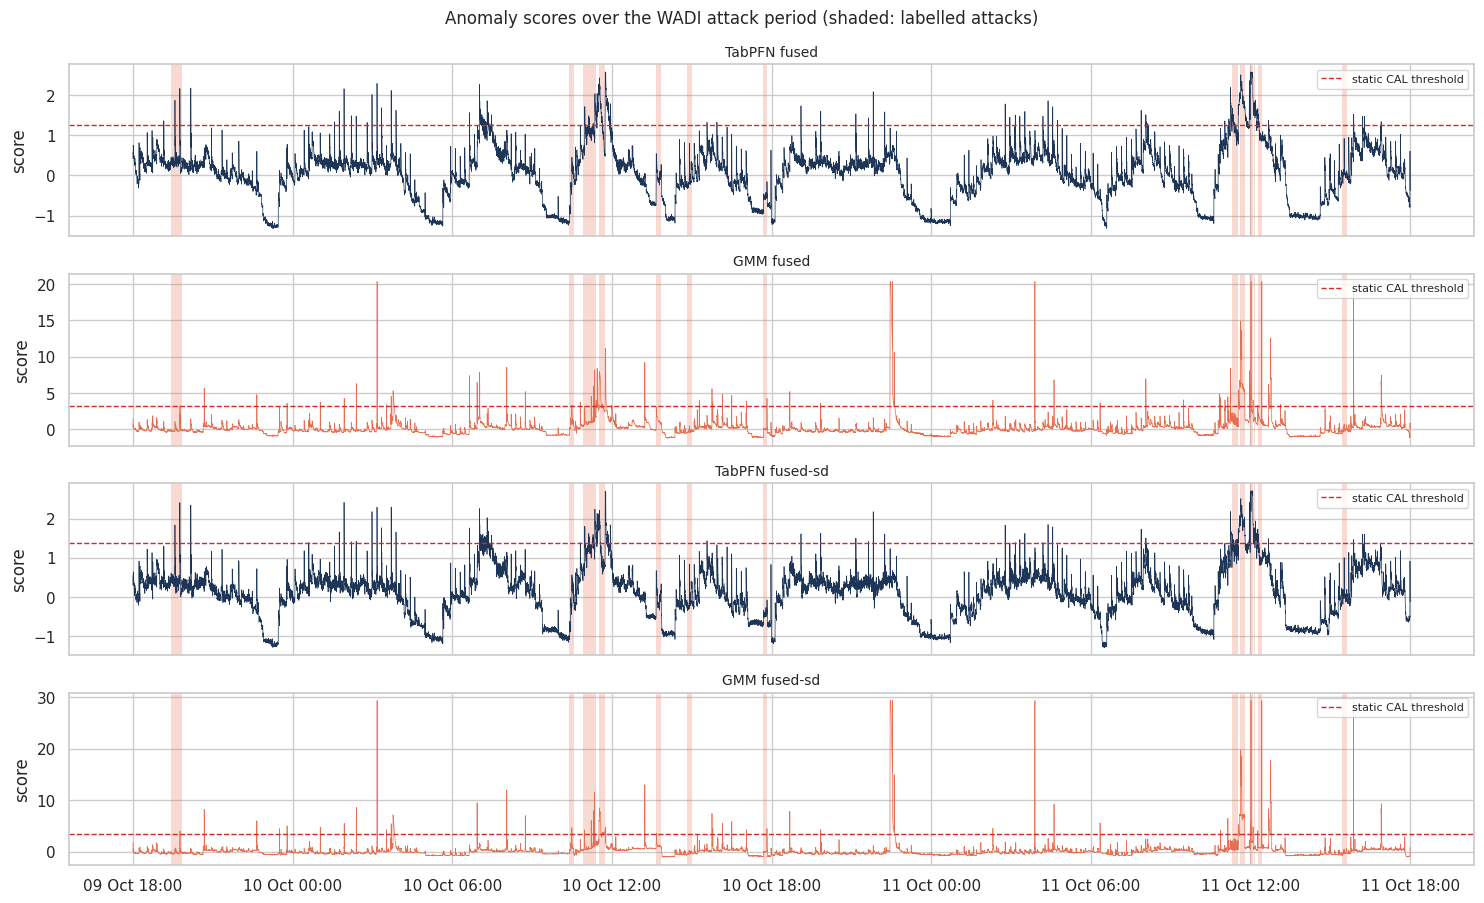

In [26]:
fig, axes = plt.subplots(len(CORE), 1, figsize=(15, 2.3 * len(CORE)), sharex=True, squeeze=False)
for ax, m in zip(axes[:, 0], CORE):
    s = score_matrix[m]
    ax.plot(ts_eval, np.clip(s, None, np.quantile(s, 0.999)), lw=0.5, color=family_color[m.split()[0]])
    ax.axhline(THRESHOLDS[m], color="#d62828", ls="--", lw=1, label="static CAL threshold")
    shade_attacks(ax, ev_segments)
    ax.set_ylabel("score")
    ax.set_title(m, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle("Anomaly scores over the WADI attack period (shaded: labelled attacks)", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_timeline")
plt.show()

### **E6. False-alarm rate per test day: static vs. adaptive threshold**

figure saved: output-figures/daily_false_alarm_rate_wadi2017_v1.png


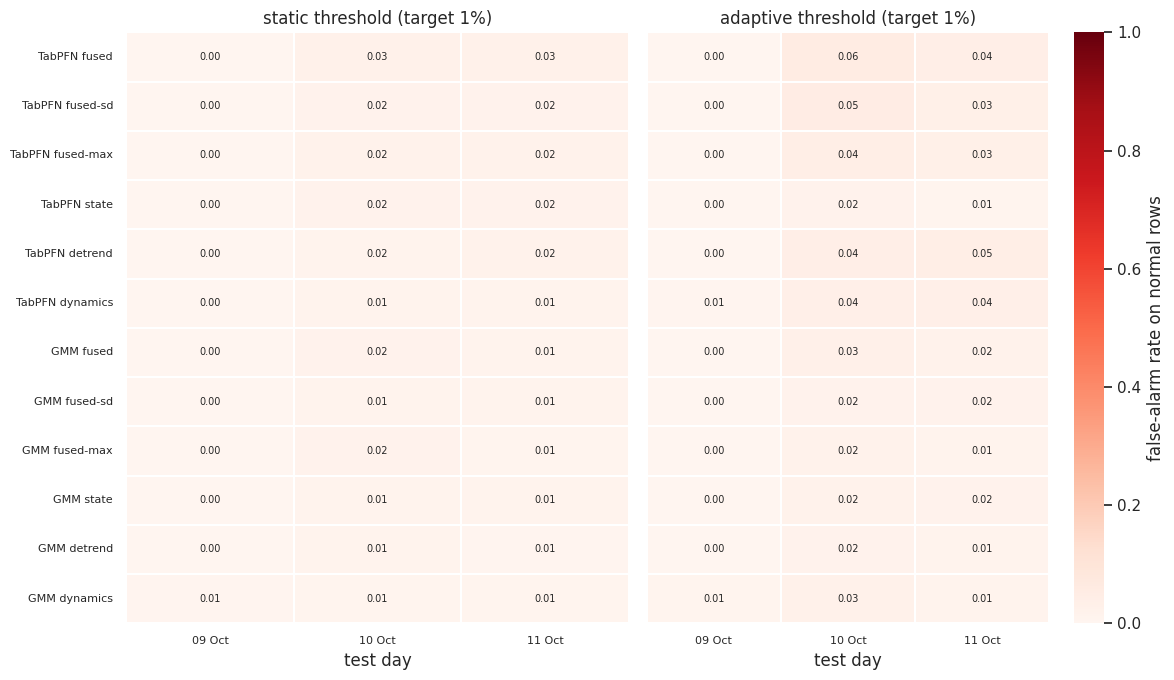

In [27]:
daily = {mode: pd.DataFrame({m: daily_false_alarm_rate(ts_eval, y_eval, s >= t) for m, (s, t) in src.items()}).T
         for mode, src in {"static": {m: (score_matrix[m], THRESHOLDS[m]) for m in names},
                           "adaptive": ADAPTIVE}.items()}
for mode, frame in daily.items():
    frame.columns = [pd.Timestamp(c).strftime("%d %b") for c in frame.columns]
    frame.to_csv(RUN_DIR / f"results_daily_false_alarm_rate_{mode}.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 0.38 * len(names) + 2.4), sharey=True)
for ax, (mode, frame) in zip(axes, daily.items()):
    sns.heatmap(frame.loc[names], annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="Reds", vmin=0, vmax=1,
                linewidths=0.3, cbar=ax is axes[-1], cbar_kws={"label": "false-alarm rate on normal rows"}, ax=ax)
    ax.grid(False)
    ax.set(xlabel="test day", ylabel="", title=f"{mode} threshold (target {target_fpr:.0%})")
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "daily_false_alarm_rate")
plt.show()

### **E7. Rank agreement and cost**

figure saved: output-figures/spearman_rank_wadi2017_v1.png


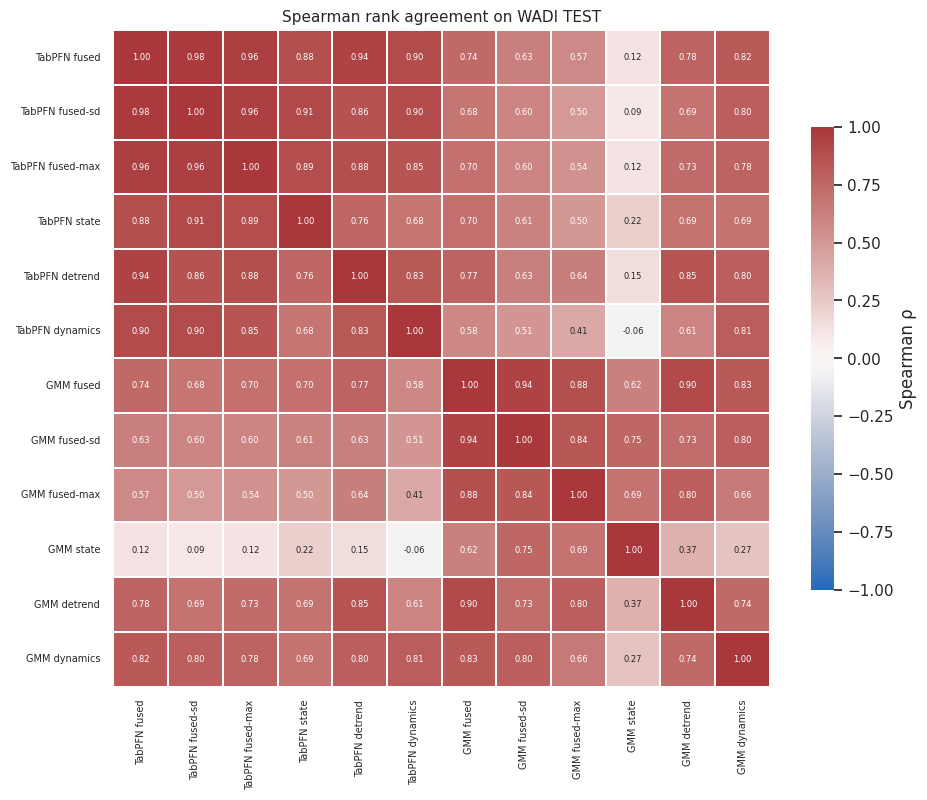

,model,ms_per_row
0,"TabPFN state (3 seeds, 54 features, GPU, batched)",111.4469
1,"TabPFN detrend (3 seeds, 35 features, GPU, bat...",63.8477
2,"TabPFN dynamics (3 seeds, 35 features, GPU, ba...",63.7109
3,"TabPFN fused (all views, GPU, batched)",239.0054
4,"GMM state (k=48, 54 features, CPU, batched)",0.0027
5,"GMM detrend (k=64, 35 features, CPU, batched)",0.0024
6,"GMM dynamics (k=64, 35 features, CPU, batched)",0.0023
7,"GMM fused (all views, CPU, batched)",0.0074


In [28]:
corr = pd.DataFrame(score_matrix).corr(method="spearman")
fig, ax = plt.subplots(figsize=(0.55 * len(names) + 3, 0.5 * len(names) + 2))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.grid(False)
ax.tick_params(labelsize=7)
ax.set_title("Spearman rank agreement on WADI TEST", fontsize=11)
plt.tight_layout()
save_fig(fig, "spearman_rank")
plt.show()

teacher_cost = pd.read_csv(TEACHER_DIR / "teacher_cost.csv")
gmm_summary = pd.read_csv(RUN_DIR / "gmm_summary.csv")
cost_rows = [{"model": f"TabPFN {v} ({len(g)} seeds, {int(g['n_features'].iloc[0])} features, GPU, batched)",
              "ms_per_row": g["ms_per_row"].sum()} for v, g in teacher_cost.groupby("view", sort=False)]
cost_rows.append({"model": "TabPFN fused (all views, GPU, batched)", "ms_per_row": teacher_cost["ms_per_row"].sum()})
cost_rows += [{"model": f"GMM {r.view} (k={r.k}, {r.n_features} features, CPU, batched)", "ms_per_row": r.ms_per_row_batched}
              for r in gmm_summary.itertuples()]
cost_rows.append({"model": "GMM fused (all views, CPU, batched)", "ms_per_row": gmm_summary["ms_per_row_batched"].sum()})
cost = pd.DataFrame(cost_rows)
cost.to_csv(RUN_DIR / "results_cost.csv", index=False)
display(cost.round(4))

## **F. Final ROC/AUC evaluation: TabPFN teacher vs. GMM baseline**

This is the headline comparison, on the same TEST rows, labels and protocol, per fusion and per view. Metrics:
- **ROC-AUC** and **average precision**, with 95% CIs from the row-block and the event bootstraps.
- **pAUC** at FPR ≤ 10%, McClish-standardised (0.5 = random, 1 = perfect).
- **TPR at 1% FPR**: the ROC operating point. It uses labels, so it is an upper bound.
- The **deployable** operating point at the static and adaptive CAL thresholds: test FPR, recall and attacks detected.

In [29]:
res = main_results.set_index(["method", "threshold_mode"])
final_rows = []
for m in names:
    s = score_matrix[m]
    st, ad = res.loc[(m, "static")], res.loc[(m, "adaptive")]
    row = {"method": m, "family": m.split()[0], "group": m.split(" ", 1)[1], "roc_auc": roc_auc_score(y_eval, s)}
    for kind in boot:
        row[f"auc_{kind}_ci_low"], row[f"auc_{kind}_ci_high"] = np.quantile(boot[kind][f"auc|{m}"], [0.025, 0.975])
    row.update({
        "average_precision": average_precision_score(y_eval, s),
        f"pauc_fpr<={ecfg['pauc_max_fpr']}": roc_auc_score(y_eval, s, max_fpr=ecfg["pauc_max_fpr"]),
        "tpr@fpr=1% (oracle)": tpr_at_fpr(y_eval, s, 0.01),
        "static: test_fpr": st["test_fpr"], "static: recall": st["recall"], "static: attacks": int(st["attacks_detected"]),
        "adaptive: roc_auc": roc_auc_score(y_eval, np.nan_to_num(ADAPTIVE[m][0], nan=0.0)),
        "adaptive: test_fpr": ad["test_fpr"], "adaptive: recall": ad["recall"], "adaptive: attacks": int(ad["attacks_detected"]),
        "adaptive: composite_f1": ad["composite_f1"],
    })
    final_rows.append(row)
final_table = pd.DataFrame(final_rows).set_index("method")
final_table.to_csv(RUN_DIR / "results_final_roc_auc.csv")
display(final_table.round(4))

,family,group,roc_auc,auc_block_ci_low,auc_block_ci_high,auc_event_ci_low,auc_event_ci_high,average_precision,pauc_fpr<=0.1,tpr@fpr=1% (oracle),static: test_fpr,static: recall,static: attacks,adaptive: roc_auc,adaptive: test_fpr,adaptive: recall,adaptive: attacks,adaptive: composite_f1
method,,,,,,,,,,,,,,,,,,
TabPFN fused,TabPFN,fused,0.7368,0.5184,0.8664,0.5747,0.8732,0.2951,0.6753,0.1619,0.0226,0.2493,8,0.7267,0.0442,0.4320,8,0.4540
TabPFN fused-sd,TabPFN,fused-sd,0.7351,0.5119,0.8704,0.5718,0.8734,0.2980,0.6713,0.1678,0.0146,0.2066,8,0.7265,0.0385,0.3803,8,0.4559
TabPFN fused-max,TabPFN,fused-max,0.7383,0.5119,0.8739,0.5758,0.8777,0.3260,0.6808,0.1986,0.0184,0.3088,8,0.7313,0.0342,0.3823,9,0.5000
TabPFN state,TabPFN,state,0.7312,0.5131,0.8690,0.5772,0.8732,0.3210,0.6795,0.1996,0.0160,0.3019,8,0.7286,0.0131,0.2363,8,0.5481
TabPFN detrend,TabPFN,detrend,0.7293,0.5403,0.8436,0.5838,0.8563,0.2561,0.6314,0.1728,0.0162,0.2175,8,0.7243,0.0377,0.2969,8,0.4164
TabPFN dynamics,TabPFN,dynamics,0.6984,0.4909,0.8262,0.5461,0.8348,0.2098,0.6202,0.1212,0.0106,0.1271,8,0.6735,0.0329,0.2433,8,0.4050
GMM fused,GMM,fused,0.7552,0.5577,0.8911,0.6035,0.8984,0.2248,0.6464,0.1043,0.0155,0.1241,8,0.7569,0.0222,0.1956,8,0.4360
GMM fused-sd,GMM,fused-sd,0.7462,0.5470,0.8829,0.5878,0.8907,0.2322,0.6515,0.1023,0.0120,0.1351,9,0.7450,0.0155,0.1778,10,0.5252
GMM fused-max,GMM,fused-max,0.7477,0.5562,0.8812,0.6008,0.8910,0.2088,0.6290,0.0943,0.0133,0.1013,7,0.7481,0.0171,0.1599,8,0.4468


figure saved: output-figures/roc_final_wadi2017_v1.png


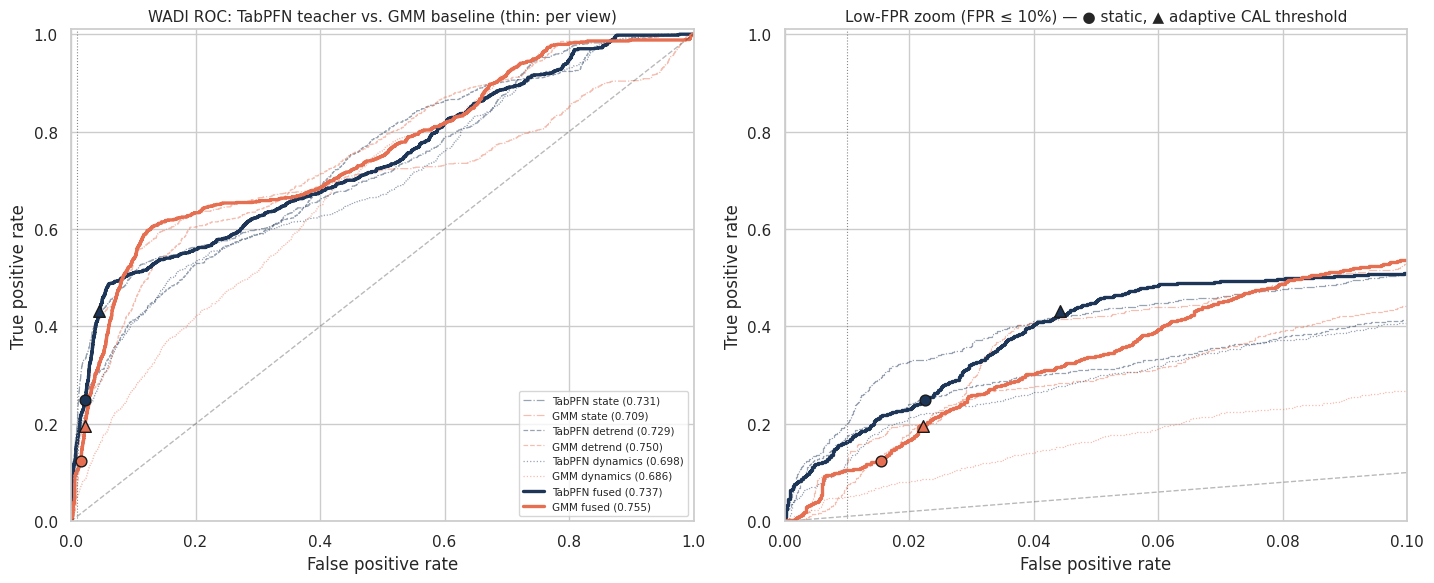

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
view_ls = {"state": "-.", "detrend": "--", "dynamics": ":"}
for ax, xmax in zip(axes, [1.0, 0.10]):
    for v in view_names:
        for fam in ["TabPFN", "GMM"]:
            m = f"{fam} {v}"
            f, t_, _ = roc_curve(y_eval, score_matrix[m])
            ax.plot(f, t_, lw=0.9, ls=view_ls.get(v, "-"), color=family_color[fam], alpha=0.45,
                    label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})" if xmax == 1.0 else None)
    for fam, m in PRIMARY.items():
        f, t_, _ = roc_curve(y_eval, score_matrix[m])
        ax.plot(f, t_, lw=2.4, color=family_color[fam], label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})")
        for mode, marker, size in [("static", "o", 60), ("adaptive", "^", 70)]:
            r = res.loc[(m, mode)]
            ax.scatter([r["test_fpr"]], [r["recall"]], color=family_color[fam], s=size, marker=marker, edgecolor="k", zorder=5)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, lw=1)
    ax.axvline(target_fpr, color="#888", lw=0.8, ls=":")
    ax.set(xlim=(0, xmax), ylim=(0, 1.01), xlabel="False positive rate", ylabel="True positive rate")
axes[0].set_title("WADI ROC: TabPFN teacher vs. GMM baseline (thin: per view)", fontsize=11)
axes[1].set_title("Low-FPR zoom (FPR ≤ 10%) — ● static, ▲ adaptive CAL threshold", fontsize=11)
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout()
save_fig(fig, "roc_final")
plt.show()

### **F2. Paired AUC differences: TabPFN − GMM**

Δ = AUC(TabPFN x) − AUC(GMM x), computed on the same bootstrap replicates, with a 95% CI from each bootstrap. A difference is supported only if the **event** CI excludes 0.

,comparison,delta_auc,block_ci_low,block_ci_high,block_ci_excludes_0,event_ci_low,event_ci_high,event_ci_excludes_0
0,TabPFN fused − GMM fused,-0.0183,-0.1727,0.1020,False,-0.1548,0.0934,False
1,TabPFN fused-sd − GMM fused-sd,-0.0111,-0.1775,0.1222,False,-0.1650,0.1164,False
2,TabPFN fused-max − GMM fused-max,-0.0095,-0.1794,0.1131,False,-0.1550,0.1053,False
3,TabPFN state − GMM state,0.0221,-0.1615,0.1863,False,-0.1517,0.1721,False
4,TabPFN detrend − GMM detrend,-0.0210,-0.1334,0.0648,False,-0.1241,0.0585,False
5,TabPFN dynamics − GMM dynamics,0.0123,-0.0872,0.0945,False,-0.1099,0.1117,False
6,TabPFN fused-sd − TabPFN fused,-0.0018,-0.0142,0.0078,False,-0.0127,0.0073,False
7,GMM fused-sd − GMM fused,-0.0090,-0.0270,0.0091,False,-0.0254,0.0085,False
8,TabPFN fused − TabPFN state,0.0056,-0.0487,0.0764,False,-0.0449,0.0722,False
9,TabPFN fused − TabPFN detrend,0.0076,-0.0337,0.0353,False,-0.0276,0.0362,False


figure saved: output-figures/auc_differences_final_wadi2017_v1.png


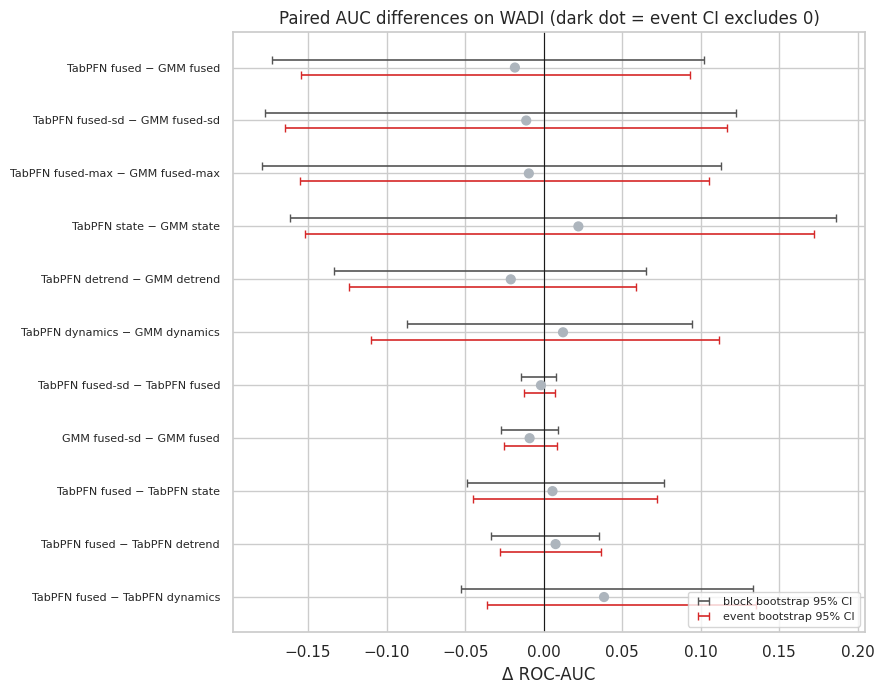

In [31]:
pairs = [(f"TabPFN {g}", f"GMM {g}") for g in GROUPS]
pairs += [(f"{fam} fused-sd", f"{fam} {ecfg['primary']}") for fam in ["TabPFN", "GMM"]]
pairs += [(f"TabPFN {ecfg['primary']}", f"TabPFN {v}") for v in view_names]
pairs = [(a, b) for a, b in pairs if a in names and b in names and a != b]

diff_rows = []
for a, b in pairs:
    row = {"comparison": f"{a} − {b}", "delta_auc": roc_auc_score(y_eval, score_matrix[a]) - roc_auc_score(y_eval, score_matrix[b])}
    for kind in boot:
        d = boot[kind][f"auc|{a}"] - boot[kind][f"auc|{b}"]
        row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(d, [0.025, 0.975])
        row[f"{kind}_ci_excludes_0"] = not (row[f"{kind}_ci_low"] <= 0 <= row[f"{kind}_ci_high"])
    diff_rows.append(row)
final_diffs = pd.DataFrame(diff_rows)
final_diffs.to_csv(RUN_DIR / "results_final_auc_differences.csv", index=False)
display(final_diffs.round(4))

fig, ax = plt.subplots(figsize=(9, 0.5 * len(final_diffs) + 1.6))
ypos = np.arange(len(final_diffs))
for off, kind, color in [(-0.15, "block", "#555"), (0.15, "event", "#d62828")]:
    ax.errorbar(final_diffs["delta_auc"], ypos + off, xerr=[final_diffs["delta_auc"] - final_diffs[f"{kind}_ci_low"],
                final_diffs[f"{kind}_ci_high"] - final_diffs["delta_auc"]], fmt="none", ecolor=color, capsize=3, lw=1.2,
                label=f"{kind} bootstrap 95% CI")
ax.scatter(final_diffs["delta_auc"], ypos, c=np.where(final_diffs["event_ci_excludes_0"], "#1d3557", "#adb5bd"), s=40, zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels(final_diffs["comparison"], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="Δ ROC-AUC", title="Paired AUC differences on WADI (dark dot = event CI excludes 0)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "auc_differences_final")
plt.show()

figure saved: output-figures/auc_tabpfn_vs_gmm_wadi2017_v1.png


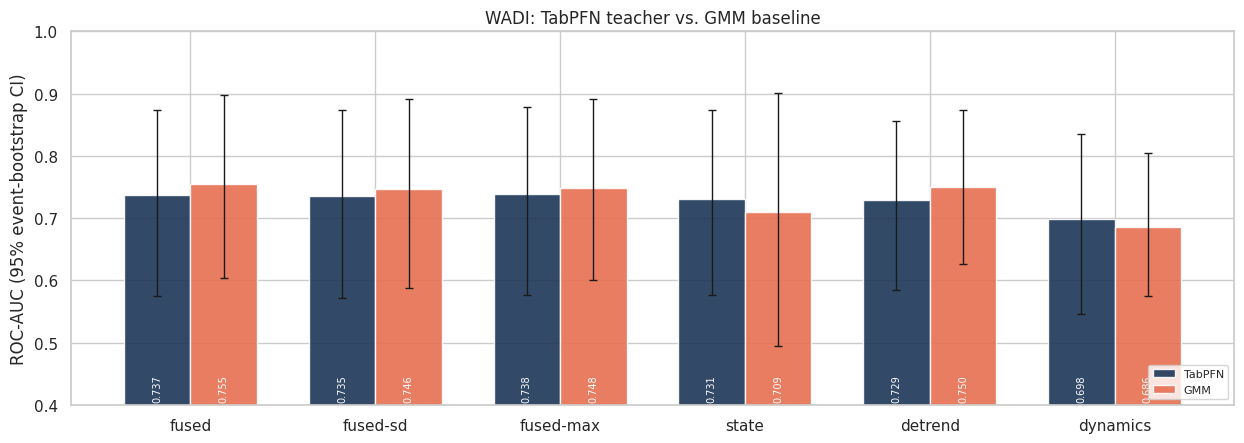

In [32]:
# TabPFN vs. GMM per fusion and per view: AUC with event-bootstrap CIs.
fig, ax = plt.subplots(figsize=(1.6 * len(GROUPS) + 3, 4.6))
width = 0.36
for j, fam in enumerate(["TabPFN", "GMM"]):
    est = np.array([final_table.loc[f"{fam} {g}", "roc_auc"] for g in GROUPS])
    lo = np.array([final_table.loc[f"{fam} {g}", "auc_event_ci_low"] for g in GROUPS])
    hi = np.array([final_table.loc[f"{fam} {g}", "auc_event_ci_high"] for g in GROUPS])
    x = np.arange(len(GROUPS)) + (j - 0.5) * width
    ax.bar(x, est, width, color=family_color[fam], label=fam, alpha=0.9)
    ax.errorbar(x, est, yerr=[est - lo, hi - est], fmt="none", ecolor="k", capsize=3, lw=1)
    for xi, e in zip(x, est):
        ax.text(xi, 0.405, f"{e:.3f}", ha="center", va="bottom", fontsize=7, color="white", rotation=90)
ax.set_xticks(np.arange(len(GROUPS)))
ax.set_xticklabels(GROUPS)
ax.set(ylim=(0.4, 1.0), ylabel="ROC-AUC (95% event-bootstrap CI)", title="WADI: TabPFN teacher vs. GMM baseline")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "auc_tabpfn_vs_gmm")
plt.show()

### **F3. Cross-dataset view: SWaT v3 vs. WADI A1 v1**

This puts the same comparison (TabPFN − GMM, per fusion and per view) side by side for both plants (A1 is the same plant data as A2, so this is not a third independent plant). The SWaT numbers are read from `results/SWaT_A1A2-full-pipeline-v3/` (block-bootstrap CIs; SWaT has no `fused-sd`). It is skipped if that run is not on disk.

,dataset,group,TabPFN AUC,GMM AUC,ΔAUC,ci_low,ci_high,ci
0,SWaT 2015 (v3),fused,0.9124,0.9318,-0.0194,-0.0453,0.0005,row-block
1,WADI A1 2017 (v1),fused,0.7368,0.7552,-0.0183,-0.1548,0.0934,event
2,SWaT 2015 (v3),state,0.7981,0.9246,-0.1265,-0.2088,-0.0676,row-block
3,WADI A1 2017 (v1),state,0.7312,0.7092,0.0221,-0.1517,0.1721,event
4,SWaT 2015 (v3),detrend,0.7347,0.8693,-0.1347,-0.1728,-0.0885,row-block
5,WADI A1 2017 (v1),detrend,0.7293,0.7502,-0.0210,-0.1241,0.0585,event
6,SWaT 2015 (v3),dynamics,0.8955,0.9049,-0.0094,-0.0299,0.0065,row-block
7,WADI A1 2017 (v1),dynamics,0.6984,0.6861,0.0123,-0.1099,0.1117,event


figure saved: output-figures/cross_dataset_tabpfn_vs_gmm_wadi2017_v1.png


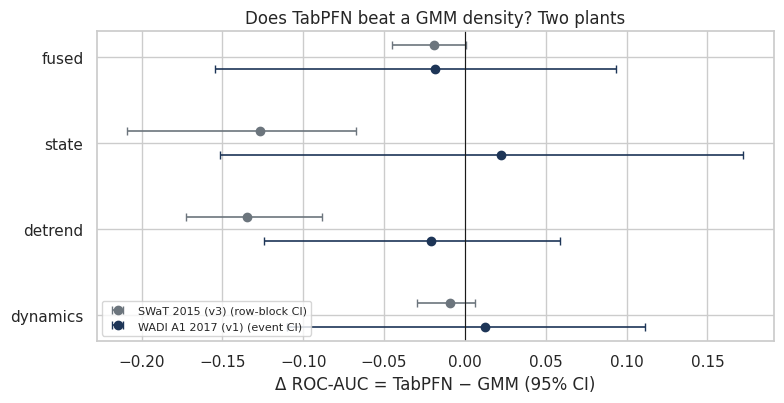

In [33]:
swat_final = SWAT_REFERENCE_DIR / "results_final_roc_auc.csv"
swat_diffs = SWAT_REFERENCE_DIR / "results_final_auc_differences.csv"
if swat_final.exists() and swat_diffs.exists():
    s_final = pd.read_csv(swat_final).set_index("method")
    s_diff = pd.read_csv(swat_diffs).set_index("comparison")
    cross_rows = []
    for g in ["fused"] + view_names:
        swat_key = f"TabPFN {g} − GMM {g}"
        if f"TabPFN {g}" in s_final.index and swat_key in s_diff.index:
            cross_rows.append({"dataset": "SWaT 2015 (v3)", "group": g,
                               "TabPFN AUC": s_final.loc[f"TabPFN {g}", "roc_auc"], "GMM AUC": s_final.loc[f"GMM {g}", "roc_auc"],
                               "ΔAUC": s_diff.loc[swat_key, "delta_auc"],
                               "ci_low": s_diff.loc[swat_key, "ci_low"], "ci_high": s_diff.loc[swat_key, "ci_high"],
                               "ci": "row-block"})
        d = final_diffs.set_index("comparison").loc[swat_key]
        cross_rows.append({"dataset": "WADI A1 2017 (v1)", "group": g,
                           "TabPFN AUC": final_table.loc[f"TabPFN {g}", "roc_auc"], "GMM AUC": final_table.loc[f"GMM {g}", "roc_auc"],
                           "ΔAUC": d["delta_auc"], "ci_low": d["event_ci_low"], "ci_high": d["event_ci_high"], "ci": "event"})
    cross = pd.DataFrame(cross_rows)
    cross.to_csv(RUN_DIR / "results_cross_dataset_tabpfn_vs_gmm.csv", index=False)
    display(cross.round(4))

    groups_c = list(dict.fromkeys(cross["group"]))
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(groups_c) + 1.8))
    for off, (ds, color) in zip([-0.14, 0.14], [("SWaT 2015 (v3)", "#6c757d"), ("WADI A1 2017 (v1)", "#1d3557")]):
        sub = cross[cross["dataset"] == ds].set_index("group").reindex(groups_c)
        ypos = np.arange(len(groups_c)) + off
        ax.errorbar(sub["ΔAUC"], ypos, xerr=[sub["ΔAUC"] - sub["ci_low"], sub["ci_high"] - sub["ΔAUC"]],
                    fmt="o", color=color, ecolor=color, capsize=3, lw=1.2, label=f"{ds} ({sub['ci'].dropna().iloc[0]} CI)")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(np.arange(len(groups_c)))
    ax.set_yticklabels(groups_c)
    ax.invert_yaxis()
    ax.set(xlabel="Δ ROC-AUC = TabPFN − GMM (95% CI)", title="Does TabPFN beat a GMM density? Two plants")
    ax.legend(fontsize=8, loc="lower left")
    plt.tight_layout()
    save_fig(fig, "cross_dataset_tabpfn_vs_gmm")
    plt.show()
else:
    print(f"SWaT v3 results not found in {SWAT_REFERENCE_DIR}; cross-dataset comparison skipped.")

### **F4. How to read the final evaluation**

1. **Does TabPFN beat the GMM on WADI?** Look at `TabPFN fused − GMM fused` (event CI) and the per-view rows. On SWaT the result was a tie. If WADI also ties, or the GMM wins, the paper reports TabPFN as matching a classical density at about 10⁴× the cost.
2. **Does the higher dimension change the picture?** WADI's views are about 2× wider than SWaT's. Check whether the state-view gap (−0.13 on SWaT) widens or narrows, and whether the seed spread of TabPFN state grows.
3. **Does dynamics carry detection again?** Compare the `dynamics` rows with the fusions, and `fused-sd` with `fused`.
4. **Does the threshold hold?** Compare the ● static and ▲ adaptive markers with the daily false-alarm heatmap (E6).

## **G. Results and figures manifest**

In [34]:
manifest = pd.DataFrame(
    [{"file": p.relative_to(RUN_DIR).as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
     for p in sorted(RUN_DIR.rglob("*")) if p.is_file()]
    + [{"file": p.as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
       for p in sorted(FIG_DIR.glob(f"*_{FIG_VERSION}.png"))]
)
display(manifest)
print(f"Run directory: {RUN_DIR.resolve()} | run {RUN_FINGERPRINT} | teacher {TEACHER_FINGERPRINT}")
print(f"Figures: {FIG_DIR.resolve()} ({len(list(FIG_DIR.glob(f'*_{FIG_VERSION}.png')))} files, {FIG_DPI} dpi)")

,file,MB
0,bootstrap_replicates_block.parquet,0.238
1,bootstrap_replicates_event.parquet,0.238
2,config.json,0.002
3,diagnostic_unseen_actuator_states.csv,0.000
4,drift_per_feature.csv,0.009
...,...,...
56,output-figures/score_distributions_wadi2017_v1...,0.646
57,output-figures/score_timeline_wadi2017_v1.png,2.103
58,output-figures/spearman_rank_wadi2017_v1.png,0.890
59,output-figures/split_and_views_wadi2017_v1.png,1.462


Run directory: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/WADi_A1_2017_full_pipeline_v1 | run 134969fe8e | teacher 7b5a98dccd
Figures: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/output-figures (14 files, 600 dpi)


In [ ]:
## **Conclusions and next steps**

Run `WADi_A1_2017_full_pipeline_v1` (TabPFN v3.5 teacher, 3 seeds × 3 views, context 5,000; no surrogate). Split: FIT 831,600 rows (1 Hz), **CAL 19,178 rows (5 Oct 16:00 → 7 Oct 21:16, A2-removed span excluded)**, TEST 17,281 rows (every 10 s) with 1,007 attack rows (5.8%) in 14 segments. The CAL fix works: the static CAL-1% threshold gives a TEST false-positive rate of 1.6–2.3%, the same range as A2. A1 and A2 share the plant data, so these results anchor the literature comparison and are **not** extra independent evidence. All CIs are event bootstrap.

### 1. Headline: a tie in AUC, as on SWaT and WADI A2

| fusion / view | TabPFN AUC | GMM AUC | ΔAUC [event 95% CI] | pAUC ≤10% FPR (TabPFN / GMM) | TPR @ 1% FPR (oracle) | static: recall · attacks |
|---|---|---|---|---|---|---|
| **fused** (primary) | 0.737 | 0.755 | **−0.018** [−0.155, +0.093] | 0.675 / 0.646 | 0.162 / 0.104 | 0.249 · 8/14 vs. 0.124 · 8/14 |
| fused-sd | 0.735 | 0.746 | −0.011 [−0.165, +0.116] | 0.671 / 0.652 | 0.168 / 0.102 | 0.207 · 8 vs. 0.135 · 9 |
| state | 0.731 | 0.709 | +0.022 [−0.152, +0.172] | 0.680 / 0.663 | 0.200 / 0.120 | 0.302 · 8 vs. 0.148 · 8 |
| detrend | 0.729 | 0.750 | −0.021 [−0.124, +0.059] | 0.631 / 0.619 | 0.173 / 0.070 | 0.217 · 8 vs. 0.050 · 5 |
| dynamics | 0.698 | 0.686 | +0.012 [−0.110, +0.112] | 0.620 / 0.557 | 0.121 / 0.050 | 0.127 · 8 vs. 0.049 · 5 |

- **No AUC difference is significant**: all 11 paired comparisons have event CIs containing 0 (about ±0.1–0.15, because there are 14 attacks). TabPFN does not beat a GMM density on full-ROC AUC on any of the three data sets.
- **Where TabPFN is ahead (point estimates, inside the CIs):** pAUC, average precision (0.295 vs. 0.225), TPR at 1% FPR (0.162 vs. 0.104), static recall (0.249 vs. 0.124) and speed to detect (median 7.5 s vs. 175 s).
- **Where TabPFN is behind:** it plateaus at 8/14 attacks at every operating point (0.5–5% target FPR), while the GMM climbs to 11/14 at 5% (recall 0.307 vs. 0.421 for TabPFN). The two detect different attacks: TabPFN finds ids 1, 3-4, 5, 10, 11, 12, 13, 14; the GMM finds 1, 2, 3-4, 5, 8, 11, 12, 14; the union is 10/14.
- **Neither detector sees** attacks 6, 7 and 9 (short or subtle: 88–736 s) and 15 is found by neither at the 1% threshold.

### 2. Threshold behaviour
Static CAL-1%: test FPR 2.3% (TabPFN) and 1.6% (GMM), with 80 and 53 false-alarm episodes. The adaptive threshold raises TabPFN's recall (0.249 → 0.432) at 4.4% FPR and 104 episodes; the GMM stays at 8/14 attacks. The adaptive threshold buys recall with false alarms and is not a clear gain.

### 3. Views and seeds
Fusing views adds nothing significant: TabPFN fused − state is +0.006 [−0.045, +0.072], fused − dynamics +0.038 [−0.036, +0.135]. The `state` view alone has the best TPR at 1% FPR (0.200). Seed spread is large for `state` (AUC 0.711 / 0.754 / 0.741), small for `detrend` (0.725–0.734) and `dynamics` (0.695–0.703).

### 4. Cost
TabPFN fused takes 239 ms per scored row (GPU, batched) against 0.0074 ms for the GMM (CPU), about 3 × 10⁴ times more. The zero-training advantage does not offset that at this level of accuracy.

### 5. What this means
1. TabPFN is **competitive with a GMM, not better**, in the same way on SWaT (ΔAUC −0.019), WADI A2 (+0.000) and WADI A1 (−0.018). The honest claim is "matches a classical density without training, at a much higher inference cost, and finds different attacks".
2. Its practical strengths are speed to detect and recall at a strict alarm budget; its weakness is the 8/14 plateau.
3. A1 adds no independent evidence; use it to compare with the literature (see `internal_comparison.tex`).

### Next steps
1. Run `WADI_A1_2017-baselines-v2.ipynb` (reads this run) and add its rows (IF, PCA, GDN, TranAD) to the comparison.
2. Add the untrained baselines of Kim et al. (input as score; randomised reconstruction model) to all three baselines notebooks. On WADI they reach F1 0.33–0.35, a bar our methods barely clear.
3. Stop reporting point-adjusted F1 except as a warning (random scores reach 0.84–0.89 here).
4. Evaluate a label-free fusion of TabPFN with TranAD, since the detectors find different attacks.


## **Conclusions and next steps**

*To be written after the run.* Fill in from `results/WADi_A1_2017_full_pipeline_v1/`: run fingerprint, teacher fingerprint, the TabPFN − GMM table (event CI), the static recall and attacks detected, and the adaptive-threshold comparison. Remember that A1 and A2 share the plant data, so these results anchor the comparison to the literature and are not extra independent evidence for WADI.

Checks to make first:
1. `CAL candidates in the A2-removed span dropped` (§2) should be ≈ 46% of the candidates, and CAL should end on 7 Oct ≈ 21:16.
2. The static CAL-1% threshold should now give a TEST false-positive rate in the low single digits for TabPFN and the GMM (A2 run: 1.9% each).
3. Then run `WADI_A1_2017-baselines.ipynb` with the matching `cal_exclude_a2_removed` change (see the top of this notebook).
